# Protein networks

The analysis of notebooks 03 and 04 (hybrid φ: screened nodes at φ = 1, all the others at the same φ)
applied to protein interaction networks. The functions are imported from `mp.py`, which collects the code written
and checked in notebook 03; message passing uses the in-place (online) update by default.

## 0. Setup

In [1]:
import time
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

from mp import (message_passing, mc_1run, curve_mc, scarto_quadratico_medio,
                matrice_G, lambda_max, matrice_M, lambda_zero, soglia_bisezione,
                estrai_protetti, phi_ibrido, phi_efficace, budget_critico, lcc_protetti,
                num_estrazioni, griglia_phi, scarto_quadratico_integrale, struttura_mp,
                message_passing_veloce, curva_mp, struttura_mc, mc_1run_veloce)

rng = np.random.default_rng(0)  # fixed seed for reproducibility

cartella_dati = Path("../data/raw/zitnik2019_treeoflife/treeoflife.interactomes")
cartella_ris = Path("risultati/06")      # csv of the long runs
cartella_ris.mkdir(exist_ok=True)

## 1. Networks

Protein interaction networks of the tree-of-life dataset of Zitnik et al. (2019), in
`data/raw/zitnik2019_treeoflife/`: one edge list per species, named by its taxonomy id. Four species with
`N` between about 1000 and 3000 nodes, the same scale as the synthetic networks of notebooks 03 and 04, so that the whole
analysis runs on the laptop. Larger networks (yeast, human) later, on a virtual machine.

We study the **whole network**, not only its largest connected component.

**Definitions.**
- **LCC** (largest connected component): the largest group of nodes connected to each other, i.e. the largest set of
  nodes in which every pair is joined by a path.
- **S Monte Carlo**: in one run the nodes fail at random, `S` = size of the LCC of the surviving nodes divided by
  **all** the `N` nodes (failed ones included); then the mean over the runs.
- **S message passing**: `S = Σ s_i / N` (course book v4, eq. 8.26), with `s_i` the probability that node `i` is
  attached to the giant component. On a finite network it counts the nodes in components that contain a cycle,
  not the largest component (notebook 05, section 3).

In [2]:
# taxonomy id in Zitnik's dataset -> short name.
# The long cells compute only the networks missing from their csv
specie = {
    1148: "Synechocystis",
    85962: "H. pylori",
    5833: "P. falciparum",
    511145: "E. coli",
}
reti = {nome: nx.read_edgelist(cartella_dati / f"{sid}.txt") for sid, nome in specie.items()}

### 1.1 Inspection

For each network: nodes, links, self-loops, degree (mean, min, max), connectedness, number of components, LCC and
second component as fractions of `N`, clustering, and the threshold of the intact network.

- **Clustering.** Mean local clustering coefficient and transitivity (3 × triangles / connected triples). Message
  passing assumes a locally tree-like network: the more triangles, the less accurate it is (notebook
  02). As a reference, an Erdős-Rényi graph with the same `N` and mean degree has clustering about
  `⟨k⟩ / (N − 1)`.
- **Degree assortativity.** Pearson correlation between the degrees at the two ends of a link (Newman, PRL 89,
  208701, 2002): positive if hubs link to hubs, negative if hubs link to low-degree nodes. It says whether the
  high-degree nodes form a connected core or act as bridges between low-degree regions.
- **Threshold.** `φ_c = 1/λ_max`, with `λ_max` the largest eigenvalue of the matrix `G` (`mp.py`, `matrice_G`), next to
  the estimate for an uncorrelated network `⟨k⟩ / (⟨k²⟩ − ⟨k⟩)` (notebook 01, section 6).

In [3]:
righe = []
for nome, g in reti.items():
    N = g.number_of_nodes()
    gradi = np.array([d for _, d in g.degree])
    componenti = sorted((len(c) for c in nx.connected_components(g)), reverse=True)
    lam = lambda_max(matrice_G(g)[0])
    righe.append({
        "network": nome, "N": N, "E": g.number_of_edges(), "self-loops": nx.number_of_selfloops(g),
        "mean degree": gradi.mean(), "min degree": gradi.min(), "max degree": gradi.max(),
        "connected": nx.is_connected(g), "components": len(componenti),
        "LCC / N": componenti[0] / N, "2nd component / N": componenti[1] / N if len(componenti) > 1 else 0.0,
        "degree assortativity": nx.degree_assortativity_coefficient(g),
        "mean clustering": nx.average_clustering(g), "transitivity": nx.transitivity(g),
        "clustering ER": gradi.mean() / (N - 1),
        "lambda_max": lam, "1/lambda_max": 1 / lam,
        "uncorrelated estimate": gradi.mean() / (np.mean(gradi ** 2) - gradi.mean()),
    })
ispezione = pd.DataFrame(righe).set_index("network")
ispezione.round(4).T

network,Synechocystis,H. pylori,P. falciparum,E. coli
N,2185,1138,1688,3068
E,6095,3027,4634,20151
self-loops,0,0,0,0
mean degree,5.5789,5.3199,5.4905,13.1362
min degree,1,1,1,1
max degree,86,40,64,245
connected,False,False,False,False
components,18,5,56,19
LCC / N,0.9835,0.9921,0.9088,0.9866
2nd component / N,0.0014,0.0026,0.0083,0.0013


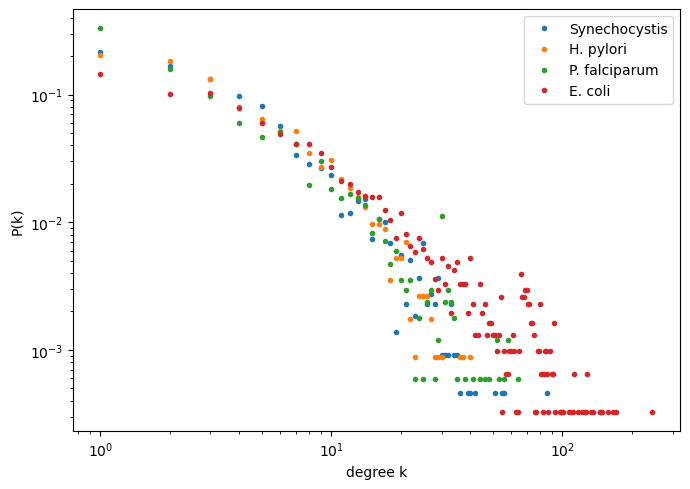

In [4]:
# degree distribution, one colour per network
fig, ax = plt.subplots(figsize=(7, 5))
for nome, g in reti.items():
    k, conteggi = np.unique([d for _, d in g.degree], return_counts=True)
    ax.loglog(k, conteggi / g.number_of_nodes(), "o", ms=3, label=nome)
ax.set_xlabel("degree k")
ax.set_ylabel("P(k)")
ax.legend()
plt.tight_layout()
plt.show()

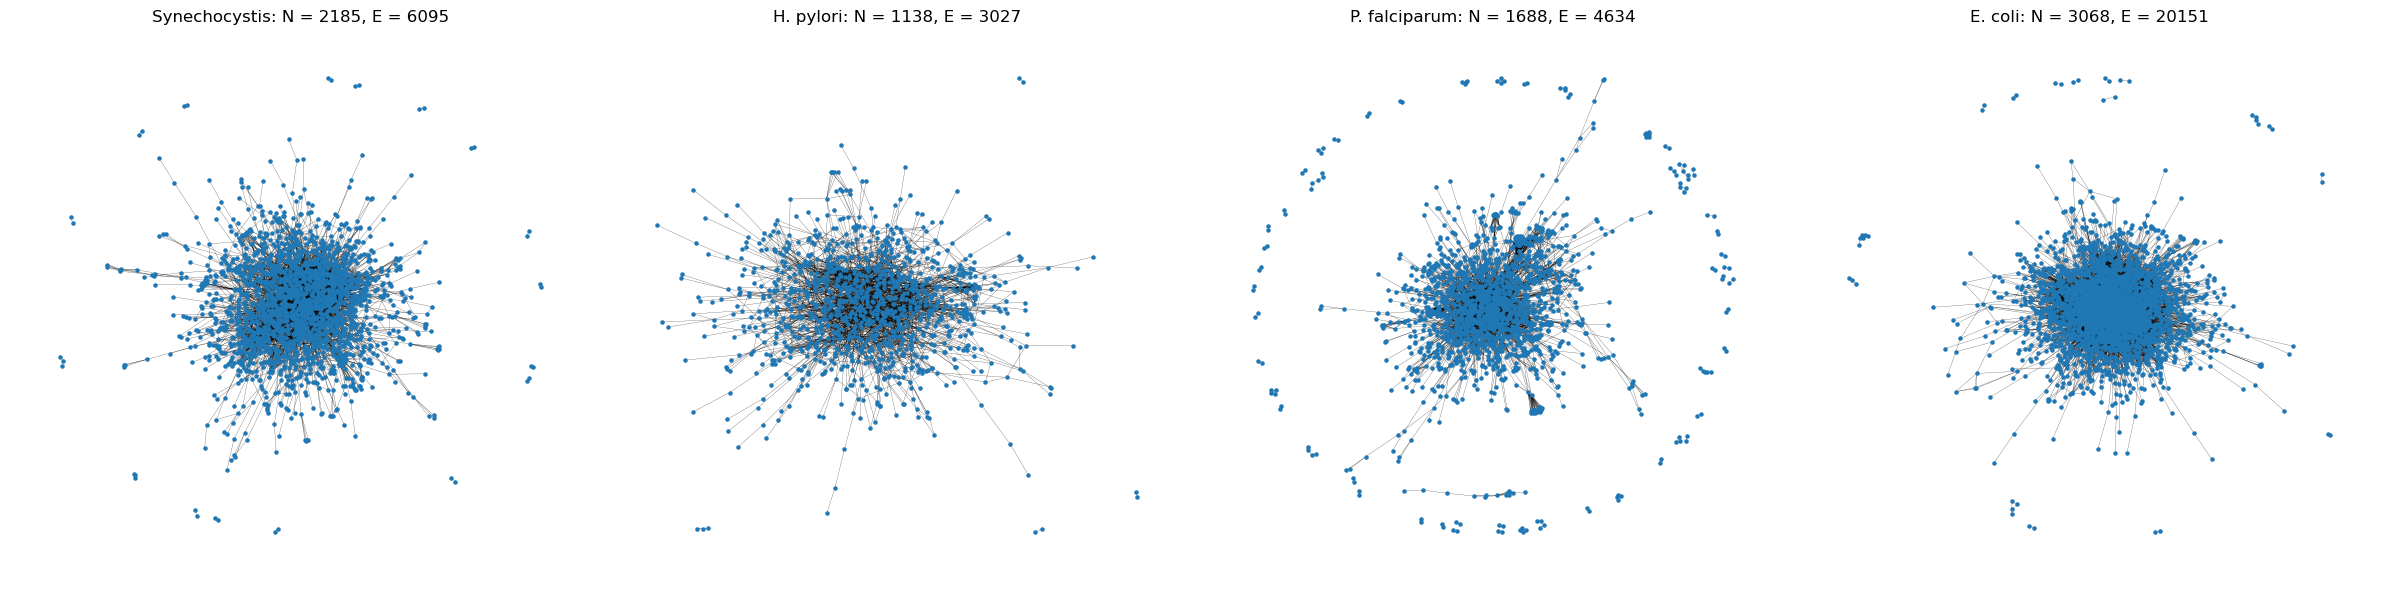

In [5]:
# node positions for the drawings (spring layout): slow, about a minute in all, to be run only once
posizioni = {nome: nx.spring_layout(g, seed=1) for nome, g in reti.items()}

fig, assi = plt.subplots(1, len(reti), figsize=(24, 6))
for ax, (nome, g) in zip(assi, reti.items()):
    nx.draw_networkx(g, posizioni[nome], ax=ax, node_size=5, width=0.15, with_labels=False, node_color="tab:blue")
    ax.set_title(f"{nome}: N = {g.number_of_nodes()}, E = {g.number_of_edges()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

#### Comment on section 1

No network is connected (18, 5, 56 and 19 components for Synechocystis, H. pylori, P. falciparum and E. coli), but the LCC holds 98.4%, 99.2%, 90.9% and 98.7% of the nodes and the second component at most 0.8% (P. falciparum, the most fragmented). No self-loops. The mean clustering (0.17, 0.15, 0.18 and 0.25) is 32 to 65 times the value of an Erdos-Renyi network with the same density (0.0026 to 0.0047): the networks are far from locally tree-like, which is the assumption behind message passing. The MP threshold 1/λ_max (0.043, 0.067, 0.034 and 0.015) is about half to two thirds of the uncorrelated estimate ⟨k⟩/(⟨k²⟩−⟨k⟩) (0.083, 0.104, 0.070 and 0.024), which uses the degree distribution only. E. coli is the densest network (mean degree 13.1 against about 5.5) and has the lowest threshold.

## 2. Screening protocols

The same three protocols as notebook 03, section 2 (`estrai_protetti` in `mp.py`): the fraction `f` of the nodes
is screened (φ = 1), chosen at **random**, by **degree** or by **betweenness**; ties are broken at random. The
betweenness and the matrix `G` do not depend on `f` or `φ`: they are computed once per network here and reused in
all the sections.

In [6]:
protocolli = ["random", "degree", "betweenness"]

t0 = time.time()
betw = {nome: nx.betweenness_centrality(g) for nome, g in reti.items()}     # about 1 minute in all
G_reti = {nome: matrice_G(g) for nome, g in reti.items()}                   # (G_mat, messaggi) of each network
str_mp = {nome: struttura_mp(g) for nome, g in reti.items()}               # arrays of the compiled solvers
str_mc = {nome: struttura_mc(g) for nome, g in reti.items()}
print(f"betweenness and G of the {len(reti)} networks in {time.time() - t0:.0f} s")

betweenness and G of the 4 networks in 164 s


### 2.1 Degree and betweenness: do they pick the same nodes?

On three of these four networks degree screening works slightly better than betweenness, while on the test networks betweenness was
the best (section 4.5). To see how different the two protocols are: the Spearman rank correlation between degree and
betweenness, and for each fraction `f` the share of nodes that the two protocols both pick (the top `f N` by degree and
by betweenness, ties broken by node order). The scatter shows betweenness against degree for every node.

Spearman rho  shared top nodes  \
network       f                                       
Synechocystis 0.001         0.784             0.500   
              0.003         0.784             0.571   
              0.010         0.784             0.409   
              0.050         0.784             0.468   
              0.100         0.784             0.509   
H. pylori     0.001         0.861             1.000   
              0.003         0.861             1.000   
              0.010         0.861             0.545   
              0.050         0.861             0.596   
              0.100         0.861             0.632   
P. falciparum 0.001         0.781             0.500   
              0.003         0.781             0.400   
              0.010         0.781             0.529   
              0.050         0.781             0.524   
              0.100         0.781             0.574   
E. coli       0.001         0.834             0.333   
              0.003         0.834             0.444   
              0.010         0.834             0.516   
              0.050         0.834             0.431   
              0.100         0.834             0.609   

                     mean degree, top betweenness  mean degree, top degree  
network       f                                                             
Synechocystis 0.001                        68.500                   71.000  
              0.003                        45.286                   52.714  
              0.010                        31.545                   39.273  
              0.050                        20.642                   26.908  
              0.100                        16.422                   21.225  
H. pylori     0.001                        40.000                   40.000  
              0.003                        37.667                   37.667  
              0.010                        27.545                   30.182  
              0.050                        19.316                   21.719  
              0.100                        15.474                   17.851  
P. falciparum 0.001                        55.500                   61.000  
              0.003                        48.600                   57.800  
              0.010                        38.000                   45.882  
              0.050                        22.917                   30.631  
              0.100                        17.278                   23.189  
E. coli       0.001                       175.667                  193.333  
              0.003                       131.889                  160.667  
              0.010                       104.097                  122.065  
              0.050                        65.536                   82.680  
              0.100                        49.736                   63.225

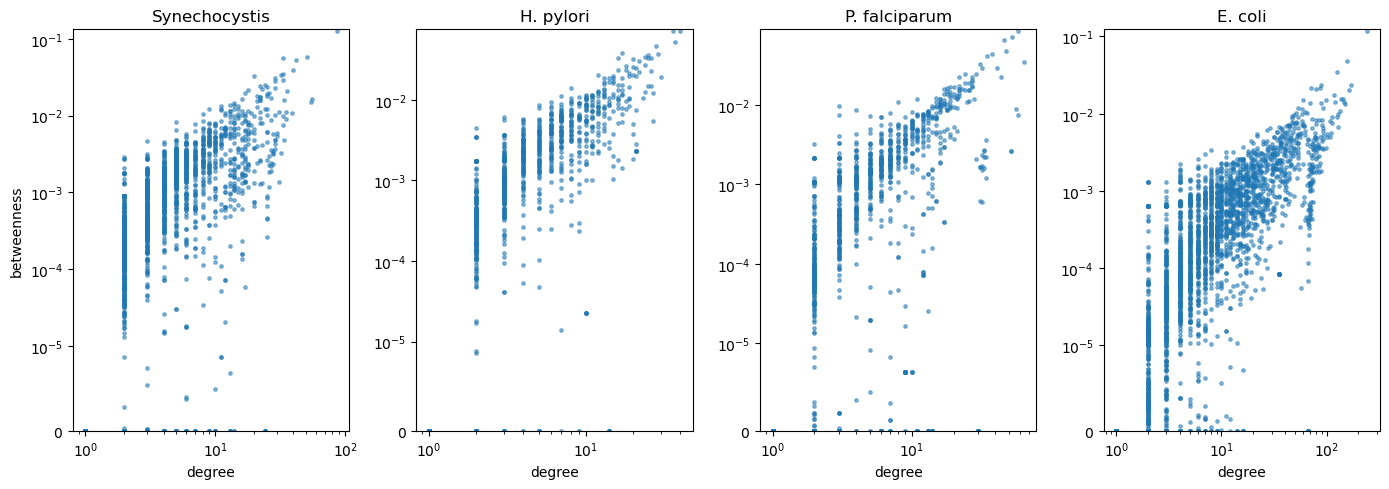

In [7]:
from scipy.stats import spearmanr

righe = []
for nome, g in reti.items():
    gradi = dict(g.degree)
    nodi = list(g.nodes)
    rho = spearmanr([gradi[n] for n in nodi], [betw[nome][n] for n in nodi])[0]
    for f in [0.001, 0.003, 0.01, 0.05, 0.10]:
        m = max(1, round(f * len(nodi)))
        top_grado = set(sorted(nodi, key=lambda n: -gradi[n])[:m])
        top_betw = set(sorted(nodi, key=lambda n: -betw[nome][n])[:m])
        righe.append({"network": nome, "Spearman rho": rho, "f": f,
                      "shared top nodes": len(top_grado & top_betw) / m,
                      "mean degree, top betweenness": np.mean([gradi[n] for n in top_betw]),
                      "mean degree, top degree": np.mean([gradi[n] for n in top_grado])})
display(pd.DataFrame(righe).set_index(["network", "f"]).round(3))

fig, assi = plt.subplots(1, len(reti), figsize=(14, 5))
for ax, (nome, g) in zip(assi, reti.items()):
    gradi = dict(g.degree)
    ax.scatter([gradi[n] for n in g], [betw[nome][n] for n in g], s=6, alpha=0.5)
    ax.set_xscale("log"); ax.set_yscale("symlog", linthresh=1e-5); ax.set_ylim(bottom=0)
    ax.set_title(nome); ax.set_xlabel("degree")
assi[0].set_ylabel("betweenness")
plt.tight_layout()
plt.show()

## 3. Check of φ_eff

As in notebook 03, section 3. For each network and each protocol, four curves `S(φ)` with the fraction `f = 0.1`
of the nodes screened:

- **(a)** message passing with a single draw of the screened nodes, kept fixed for all the values of `φ` (quenched);
- **(b)** the same with `num_estrazioni_3` independent draws, mean and standard deviation over the draws;
- **(c)** message passing with `φ_i = φ_eff` for all the nodes (annealed);
- **(d)** Monte Carlo with the same draw as (a).

`φ_eff` holds only for the **random** protocol, so (c) is the same curve for all the protocols: with random
screening (b) and (c) must agree within the spread over the draws; with degree and betweenness (c) is the reference.

**Grid of φ.** The thresholds of the intact networks are below 0.1 (section 1.1), so the grid is
finer at small `φ`: step 0.01 up to 0.1, then 0.05. The `φ` axis of the plots is linear.

**Long run.** About 1000 message passing solves per network: about 10 minutes on P. falciparum, 20 on
Synechocystis, 2 hours on E. coli (estimates from one solve at φ = 0.3).
The results are saved in `risultati/06/curve_phi_eff.csv` after each network; the networks already in the file are
not computed again (delete the file to run everything again).

In [8]:
phis = np.round(np.concatenate([np.arange(0, 0.1, 0.01), np.arange(0.1, 1.0001, 0.05)]), 3)   # 29 values
frazione = 0.1                     # fraction of the nodes screened
num_estrazioni_3 = 10              # independent draws of the screened nodes for (b)
num_runs_mc = 50                   # Monte Carlo runs per value of phi for (d)

file_3 = cartella_ris / "curve_phi_eff.csv"
curve_eff = pd.read_csv(file_3) if file_3.exists() else pd.DataFrame(columns=["network"])

for nome, g in reti.items():
    if nome in set(curve_eff["network"]):
        continue      # already computed: read from the csv
    t0 = time.time()
    righe = []

    # (c) annealed: the same phi_eff for all the nodes, the same for all the protocols
    S_c = curva_mp(g, phi_efficace(phis, frazione), struttura=str_mp[nome])

    for protocollo in protocolli:
        # (a) a single draw, fixed for all the values of phi
        protetti_a = estrai_protetti(g, frazione, protocollo, rng, betw[nome])
        S_a = curva_mp(g, phis, protetti_a, str_mp[nome])

        # (b) a new draw for each curve, one row per draw
        S_b = []
        for e in range(num_estrazioni_3):
            protetti = estrai_protetti(g, frazione, protocollo, rng, betw[nome])
            S_b.append(curva_mp(g, phis, protetti, str_mp[nome]))
        S_b = np.array(S_b)

        # (d) Monte Carlo with the draw of (a): the dict of the phi_i is built once per phi
        S_d = []
        for phi in phis:
            phi_n = phi_ibrido(g, protetti_a, phi)
            S_d.append(np.mean([mc_1run_veloce(g, phi_n, rng, str_mc[nome]) for _ in range(num_runs_mc)]))

        for k, phi in enumerate(phis):
            righe.append({"network": nome, "protocol": protocollo, "phi": phi, "a": S_a[k],
                          "b mean": S_b[:, k].mean(), "b std": S_b[:, k].std(), "c": S_c[k], "d": S_d[k]})

    curve_eff = pd.concat([curve_eff, pd.DataFrame(righe)], ignore_index=True)
    curve_eff.to_csv(file_3, index=False)      # saved after each network
    print(f"{nome}: {time.time() - t0:.0f} s")

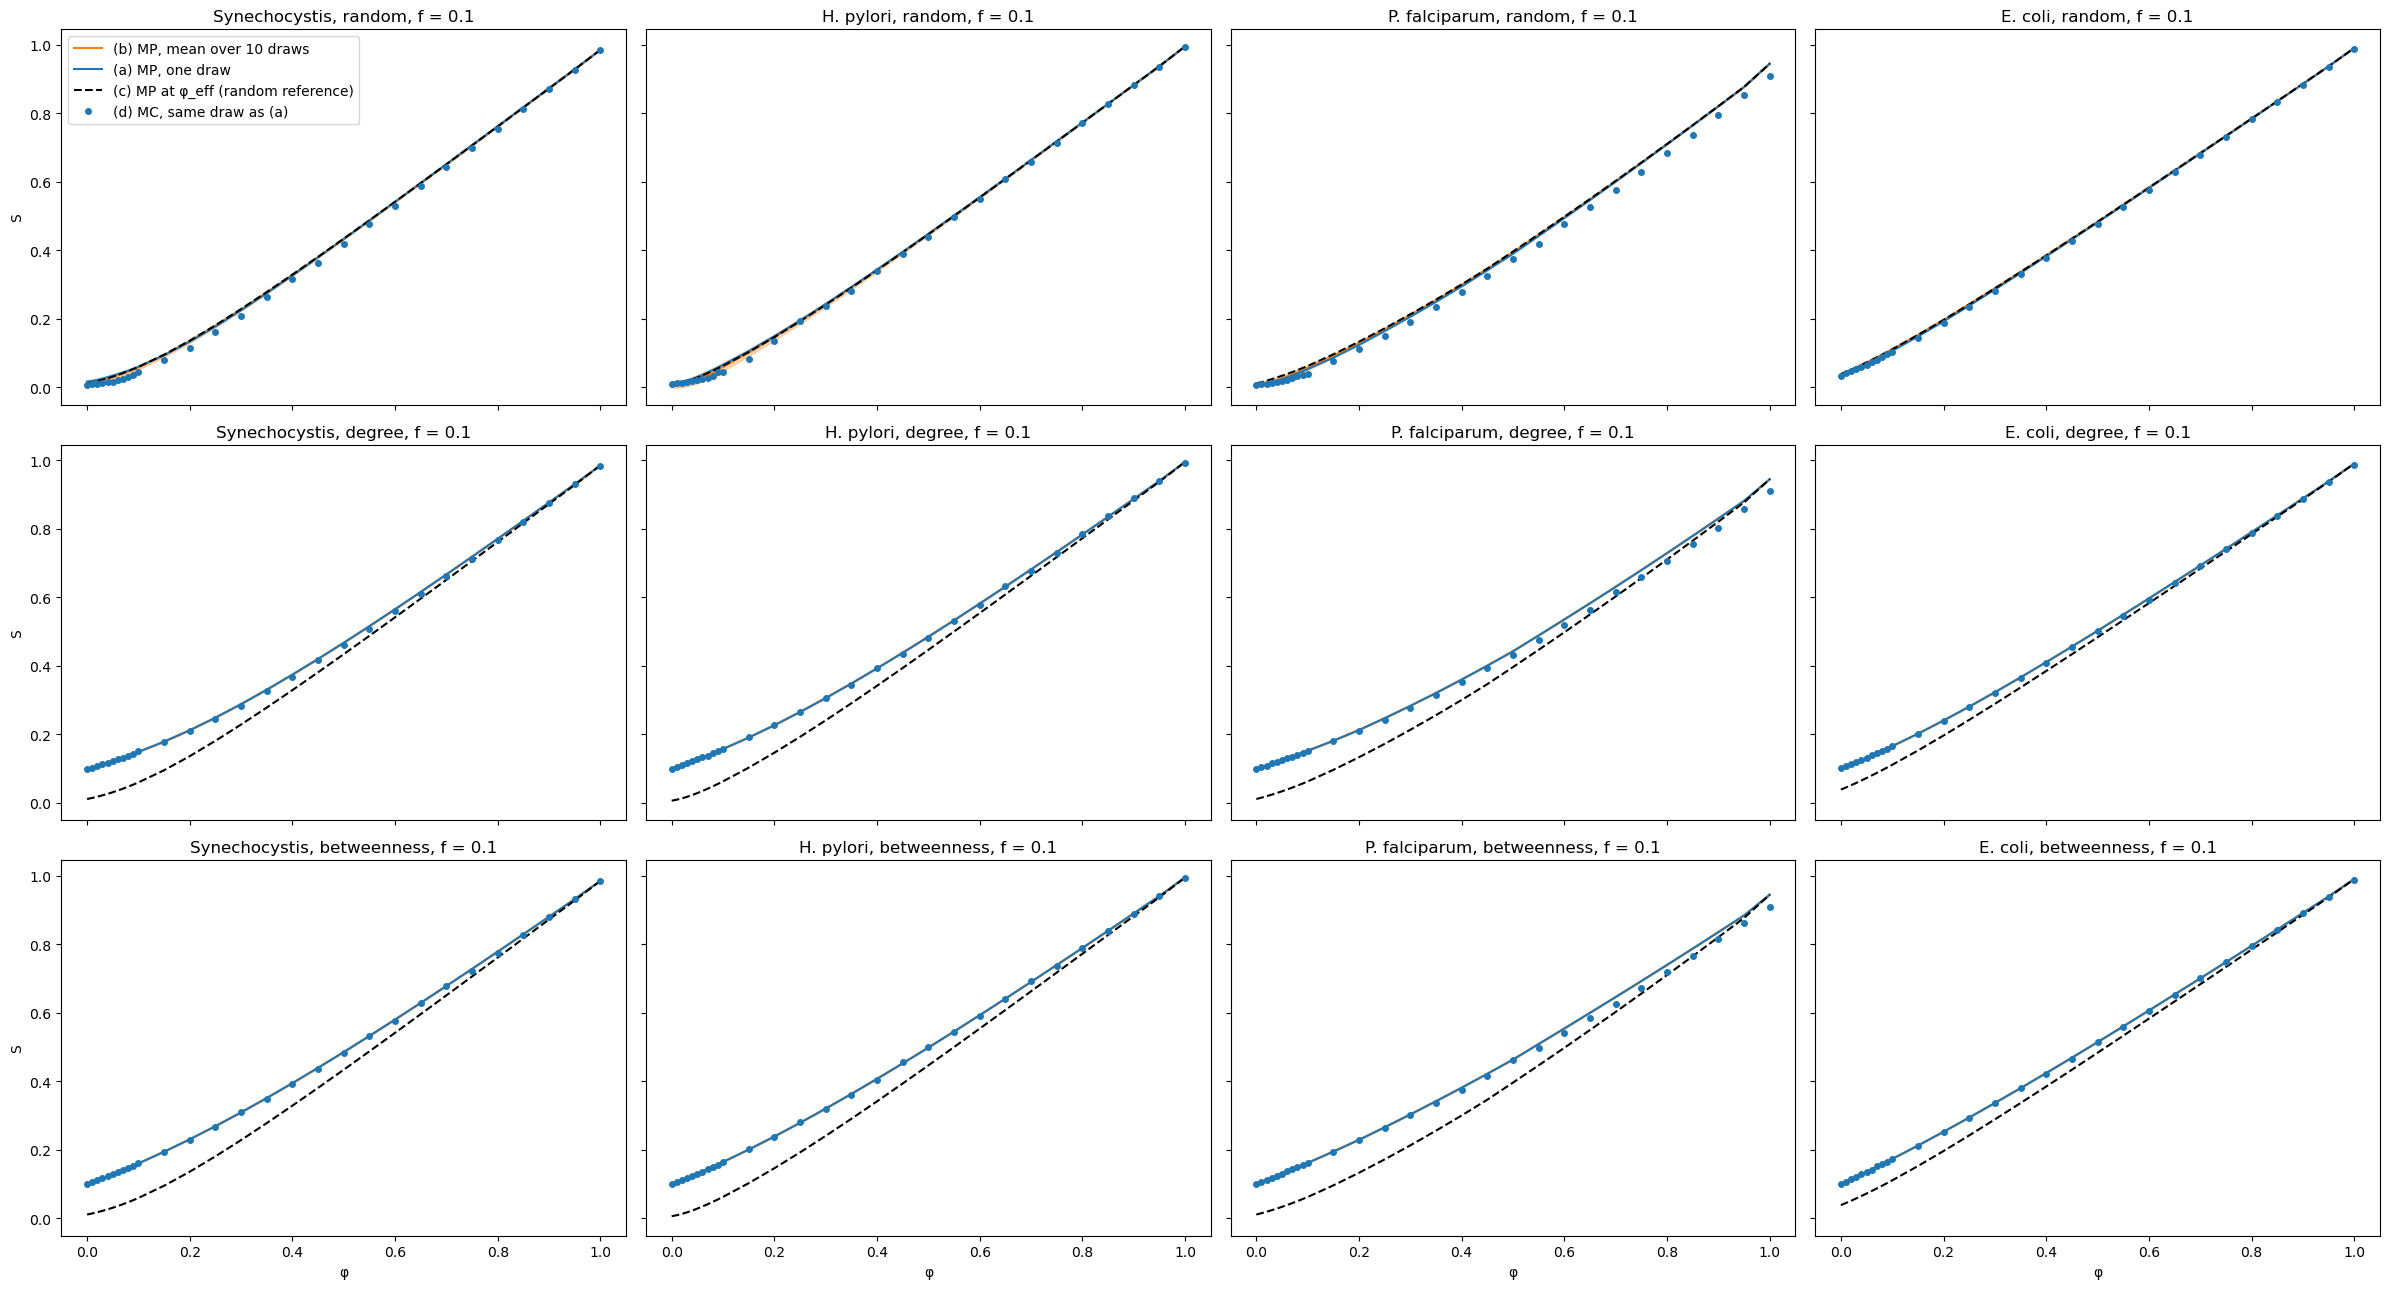

In [9]:
# the four curves: one row per protocol, one column per network
fig, assi = plt.subplots(len(protocolli), len(reti), figsize=(24, 13), sharex=True, sharey=True)
for r, protocollo in enumerate(protocolli):
    for col, nome in enumerate(reti):
        ax = assi[r, col]
        t = curve_eff[(curve_eff["network"] == nome) & (curve_eff["protocol"] == protocollo)]
        ax.fill_between(t["phi"], t["b mean"] - t["b std"], t["b mean"] + t["b std"], color="tab:orange", alpha=0.3)
        ax.plot(t["phi"], t["b mean"], color="tab:orange", label=f"(b) MP, mean over {num_estrazioni_3} draws")
        ax.plot(t["phi"], t["a"], color="tab:blue", label="(a) MP, one draw")
        ax.plot(t["phi"], t["c"], "k--", label="(c) MP at φ_eff (random reference)")
        ax.plot(t["phi"], t["d"], "o", color="tab:blue", ms=4, label="(d) MC, same draw as (a)")
        ax.set_title(f"{nome}, {protocollo}, f = {frazione}")
    assi[r, 0].set_ylabel("S")
for ax in assi[-1]:
    ax.set_xlabel("φ")
assi[0, 0].legend()
plt.tight_layout()
plt.show()

In [10]:
# RMS deviation between the curves, one row per network and protocol
rms_eff = pd.DataFrame({
    (nome, protocollo): {"b vs c": scarto_quadratico_medio(t["b mean"], t["c"]),
                         "a vs d": scarto_quadratico_medio(t["a"], t["d"]),
                         "b vs d": scarto_quadratico_medio(t["b mean"], t["d"]),
                         "c vs d": scarto_quadratico_medio(t["c"], t["d"]),
                         "max b std": t["b std"].max()}
    for (nome, protocollo), t in curve_eff.groupby(["network", "protocol"], sort=False)
}).T
rms_eff.round(4)

b vs c  a vs d  b vs d  c vs d  max b std
Synechocystis random       0.0010  0.0129  0.0118  0.0127     0.0055
              degree       0.0641  0.0038  0.0036  0.0631     0.0004
              betweenness  0.0738  0.0020  0.0020  0.0730     0.0000
H. pylori     random       0.0025  0.0097  0.0072  0.0081     0.0128
              degree       0.0690  0.0022  0.0025  0.0690     0.0009
              betweenness  0.0754  0.0017  0.0017  0.0749     0.0000
P. falciparum random       0.0042  0.0172  0.0196  0.0217     0.0087
              degree       0.0678  0.0138  0.0140  0.0656     0.0003
              betweenness  0.0778  0.0127  0.0127  0.0754     0.0000
E. coli       random       0.0003  0.0034  0.0063  0.0061     0.0043
              degree       0.0407  0.0017  0.0017  0.0404     0.0001
              betweenness  0.0468  0.0015  0.0015  0.0463     0.0000

#### Comment on section 3

With f = 0.1, the annealed curve with φ_eff (c) follows the average over the draws (b) only for random screening (RMS 0.0003 to 0.0042). For degree and betweenness the RMS is 0.041 to 0.078: a single φ_eff for all the nodes loses which nodes are screened. Message passing and Monte Carlo on the same draw (a vs d) differ by RMS 0.0015 to 0.017: the largest values are on P. falciparum (0.013 to 0.017 with every protocol) and, on the other networks, with random screening. The spread over the draws (max b std) is 0.004 to 0.013 for random, at most 0.001 for degree and 0 for betweenness.

## 4. Critical threshold for each protocol

### 4.1 The matrix M = diag(φ) G

Checks of `matrice_M` (notebook 03, section 4.1): with uniform `φ`, `λ(M) = φ λ_max(G)`; with `φ = 1` for all the
nodes, `λ(M) = λ_max(G)`.

In [11]:
phi_prova = 0.3
for nome, g in reti.items():
    G_mat, messaggi = G_reti[nome]
    lam_G = lambda_max(G_mat)
    lam_1 = lambda_max(matrice_M(G_mat, messaggi, {n: phi_prova for n in g}))
    lam_2 = lambda_max(matrice_M(G_mat, messaggi, {n: 1.0 for n in g}))
    print(f"{nome}: lambda_max(G) = {lam_G:.6f}")
    print(f"  1) phi = {phi_prova}: lambda(M) = {lam_1:.6f}, phi * lambda_max = {phi_prova * lam_G:.6f}")
    print(f"  2) phi = 1:   lambda(M) = {lam_2:.6f}")

Synechocystis: lambda_max(G) = 23.059341
  1) phi = 0.3: lambda(M) = 6.917802, phi * lambda_max = 6.917802
  2) phi = 1:   lambda(M) = 23.059341
H. pylori: lambda_max(G) = 14.848570
  1) phi = 0.3: lambda(M) = 4.454571, phi * lambda_max = 4.454571
  2) phi = 1:   lambda(M) = 14.848570
P. falciparum: lambda_max(G) = 29.013657
  1) phi = 0.3: lambda(M) = 8.704097, phi * lambda_max = 8.704097
  2) phi = 1:   lambda(M) = 29.013657


E. coli: lambda_max(G) = 65.143047
  1) phi = 0.3: lambda(M) = 19.542914, phi * lambda_max = 19.542914
  2) phi = 1:   lambda(M) = 65.143047


### 4.2 λ(φ) is non-decreasing

As in notebook 03, section 4.2, with `f = 0.05`: `λ(φ)` for the three protocols against `φ_eff`, and the numerical
check that it never goes down as `φ` grows. The bisection of section 4.3 relies on it. The `λ` axis is linear below
1 and logarithmic above, so that the crossing of 1 is visible.

Synechocystis, random: non-decreasing True, lambda(0) = 0.000, lambda(1) = 23.059


Synechocystis, degree: non-decreasing True, lambda(0) = 23.048, lambda(1) = 23.059


Synechocystis, betweenness: non-decreasing True, lambda(0) = 6.328, lambda(1) = 23.059


H. pylori, random: non-decreasing True, lambda(0) = 1.000, lambda(1) = 14.849


H. pylori, degree: non-decreasing True, lambda(0) = 12.422, lambda(1) = 14.849


H. pylori, betweenness: non-decreasing True, lambda(0) = 3.883, lambda(1) = 14.849


... (2 outputs left out)

P. falciparum, betweenness: non-decreasing True, lambda(0) = 6.646, lambda(1) = 29.014


E. coli, random: non-decreasing True, lambda(0) = 2.000, lambda(1) = 65.143


E. coli, degree: non-decreasing True, lambda(0) = 65.025, lambda(1) = 65.143


E. coli, betweenness: non-decreasing True, lambda(0) = 31.273, lambda(1) = 65.143


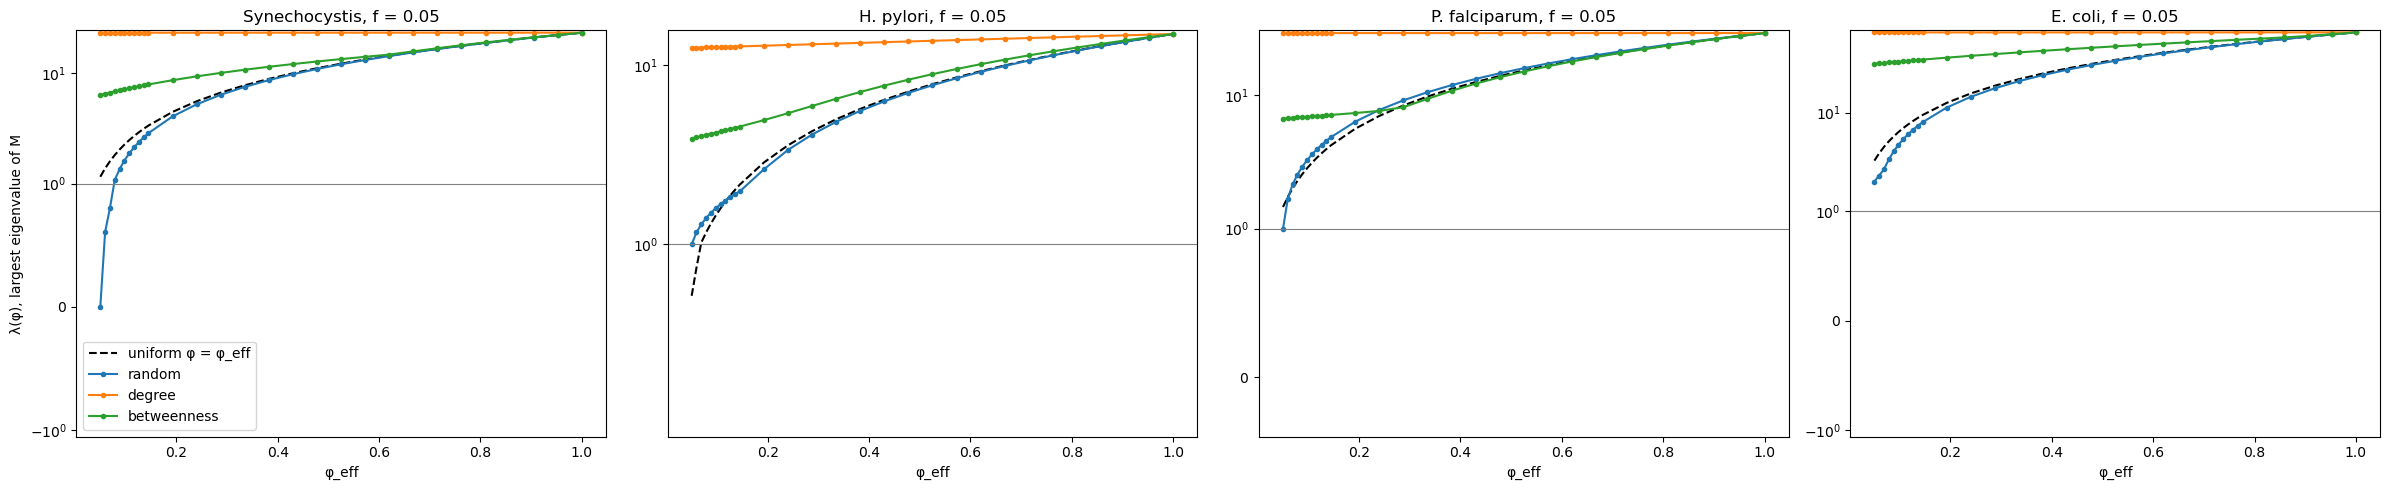

In [12]:
frazione_42 = 0.05

fig, assi = plt.subplots(1, len(reti), figsize=(24, 5))
for ax, (nome, g) in zip(assi, reti.items()):
    G_mat, messaggi = G_reti[nome]
    phi_eff = phi_efficace(phis, frazione_42)

    # uniform phi at phi_eff: lambda = phi_eff * lambda_max (section 4.1)
    ax.plot(phi_eff, phi_eff * lambda_max(G_mat), "k--", label="uniform φ = φ_eff")

    for protocollo in protocolli:
        protetti = estrai_protetti(g, frazione_42, protocollo, rng, betw[nome])
        # at phi = 0 lambda_zero (subgraph of the screened nodes): there eigs is not reliable
        lam = [lambda_zero(g, protetti) if phi == 0 else
               lambda_max(matrice_M(G_mat, messaggi, phi_ibrido(g, protetti, phi))) for phi in phis]
        ax.plot(phi_eff, lam, "o-", ms=3, label=protocollo)
        print(f"{nome}, {protocollo}: non-decreasing {np.all(np.diff(lam) >= -1e-9)}, "
              f"lambda(0) = {lam[0]:.3f}, lambda(1) = {lam[-1]:.3f}")

    ax.axhline(1, color="gray", lw=0.8)
    ax.set_yscale("symlog", linthresh=1)
    ax.set_title(f"{nome}, f = {frazione_42}")
    ax.set_xlabel("φ_eff")
assi[0].set_ylabel("λ(φ), largest eigenvalue of M")
assi[0].legend()
plt.tight_layout()
plt.show()

### 4.3 Threshold by bisection

`λ_max` is computed with `eigs` (ARPACK); the bisection looks for the `φ` where `λ(M(φ)) = 1` (`soglia_bisezione`).
Checks as in notebook 03, section 4.3: (1) with `f = 0` the bisection must give `1/λ_max`; (2) random screening
with `f = 0.05` must be close to the annealed value `(1/λ_max − f)/(1 − f)`, cut at 0.

In [13]:
frazione_43 = 0.05
for nome, g in reti.items():
    G_mat, messaggi = G_reti[nome]
    lam_G = lambda_max(G_mat)
    phi_c_0 = soglia_bisezione(g, G_mat, messaggi, [])
    print(f"{nome}: 1) f = 0: phi_c = {phi_c_0:.5f}, 1/lambda_max = {1 / lam_G:.5f}")

    soglie = [soglia_bisezione(g, G_mat, messaggi, estrai_protetti(g, frazione_43, "random", rng))
              for _ in range(5)]
    print(f"  2) random, f = {frazione_43}: phi_c = {np.mean(soglie):.4f} ± {np.std(soglie):.4f}, "
          f"annealed = {max(0, (1 / lam_G - frazione_43) / (1 - frazione_43)):.4f}")

Synechocystis: 1) f = 0: phi_c = 0.04337, 1/lambda_max = 0.04337


  2) random, f = 0.05: phi_c = 0.0097 ± 0.0088, annealed = 0.0000


H. pylori: 1) f = 0: phi_c = 0.06735, 1/lambda_max = 0.06735


  2) random, f = 0.05: phi_c = 0.0198 ± 0.0173, annealed = 0.0183


P. falciparum: 1) f = 0: phi_c = 0.03445, 1/lambda_max = 0.03447


  2) random, f = 0.05: phi_c = 0.0139 ± 0.0138, annealed = 0.0000


E. coli: 1) f = 0: phi_c = 0.01535, 1/lambda_max = 0.01535
  2) random, f = 0.05: phi_c = 0.0000 ± 0.0000, annealed = 0.0000


### 4.4 φ_c for each protocol

For each network, protocol and fraction `f`, `φ_c` from the bisection. `f` from 0 to 30 screened nodes out of 1000,
one step of 0.001 at a time, plus `f = 0.05, 0.10, 0.25` as a reference for large screening, as in notebook 04,
section 1.1. Number of draws from `num_estrazioni` (`mp.py`): one when the protocol always picks the same set of
nodes, otherwise `round(30/n) + 10`, with `n` the number of screened nodes. Saved in
`risultati/06/soglie_protocolli_fpiccole.csv` after each network.

In [14]:
frazioni_44 = [n / 1000 for n in range(31)] + [0.05, 0.10, 0.25]   # 0 to 30 screened nodes out of 1000, then large f

file_44 = cartella_ris / "soglie_protocolli_fpiccole.csv"
soglie_prot = pd.read_csv(file_44) if file_44.exists() else pd.DataFrame(columns=["network"])

for nome, g in reti.items():
    if nome in set(soglie_prot["network"]):
        continue      # already computed: read from the csv
    t0 = time.time()
    G_mat, messaggi = G_reti[nome]
    righe = []
    for protocollo in protocolli:
        for frazione in frazioni_44:
            for e in range(num_estrazioni(g, frazione, protocollo, betw[nome])):
                protetti = estrai_protetti(g, frazione, protocollo, rng, betw[nome])
                righe.append({"network": nome, "protocol": protocollo, "f": frazione, "draw": e,
                              "phi_c": soglia_bisezione(g, G_mat, messaggi, protetti)})
    soglie_prot = pd.concat([soglie_prot, pd.DataFrame(righe)], ignore_index=True)
    soglie_prot.to_csv(file_44, index=False)      # saved after each network
    print(f"{nome}: {time.time() - t0:.0f} s")

In [15]:
# mean and standard deviation of phi_c over the draws, and number of draws: one row per (network, protocol);
# the table shows only some values of f, the plot below has all of them
sintesi_44 = soglie_prot.groupby(["network", "protocol", "f"], sort=False)["phi_c"].agg(["mean", "std", "count"])
f_tabella = [0.0, 0.001, 0.003, 0.01, 0.03, 0.05, 0.10, 0.25]
sintesi_44["mean"].unstack("f")[f_tabella].round(4)

f                           0.000   0.001   0.003   0.010   0.030   0.050  \
network       protocol                                                      
Synechocystis random       0.0434  0.0427  0.0417  0.0348  0.0197  0.0085   
              degree       0.0434  0.0258  0.0000  0.0000  0.0000  0.0000   
              betweenness  0.0434  0.0417  0.0409  0.0000  0.0000  0.0000   
H. pylori     random       0.0674  0.0673  0.0663  0.0607  0.0384  0.0232   
              degree       0.0674  0.0638  0.0605  0.0000  0.0000  0.0000   
              betweenness  0.0674  0.0638  0.0605  0.0000  0.0000  0.0000   
P. falciparum random       0.0345  0.0329  0.0336  0.0326  0.0228  0.0084   
              degree       0.0345  0.0172  0.0000  0.0000  0.0000  0.0000   
              betweenness  0.0345  0.0342  0.0000  0.0000  0.0000  0.0000   
E. coli       random       0.0154  0.0139  0.0128  0.0110  0.0004  0.0000   
              degree       0.0154  0.0034  0.0000  0.0000  0.0000  0.0000   
              betweenness  0.0154  0.0073  0.0000  0.0000  0.0000  0.0000   

f                           0.100  0.250  
network       protocol                    
Synechocystis random       0.0000    0.0  
              degree       0.0000    0.0  
              betweenness  0.0000    0.0  
H. pylori     random       0.0046    0.0  
              degree       0.0000    0.0  
              betweenness  0.0000    0.0  
P. falciparum random       0.0000    0.0  
              degree       0.0000    0.0  
              betweenness  0.0000    0.0  
E. coli       random       0.0000    0.0  
              degree       0.0000    0.0  
              betweenness  0.0000    0.0

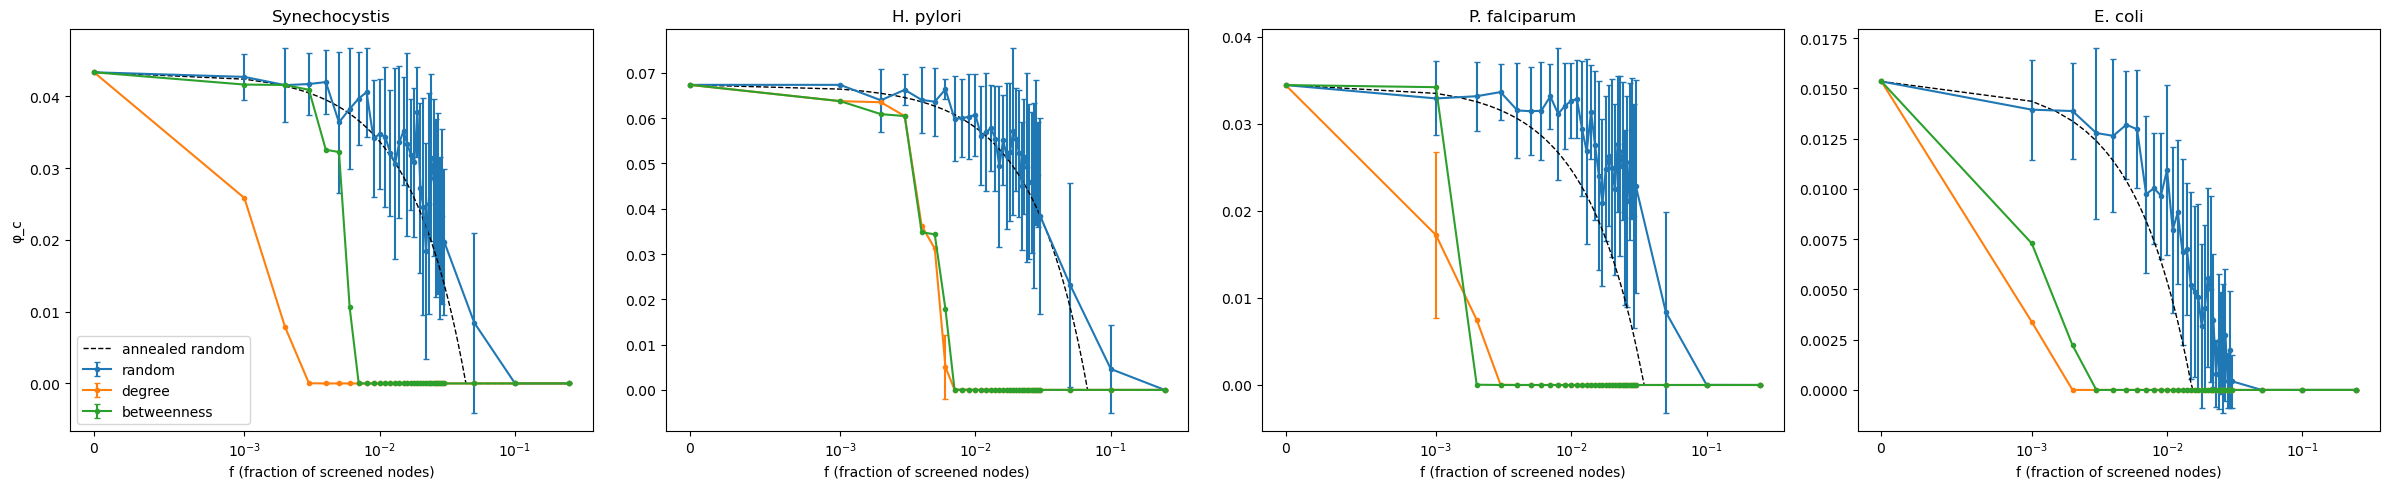

In [16]:
# phi_c against f, one panel per network, one line per protocol;
# dashed: annealed random screening, phi_c = (1/lambda_max - f)/(1 - f), cut at 0
fig, assi = plt.subplots(1, len(reti), figsize=(24, 5))
for ax, (nome, g) in zip(assi, reti.items()):
    for protocollo in protocolli:
        t = sintesi_44.loc[(nome, protocollo)]
        ax.errorbar(t.index, t["mean"], yerr=t["std"], fmt="o-", ms=3, capsize=2, label=protocollo)
    inv_lam = 1 / lambda_max(G_reti[nome][0])
    f_fine = np.linspace(0, max(frazioni_44), 500)
    ax.plot(f_fine, np.maximum(0, (inv_lam - f_fine) / (1 - f_fine)), "k--", lw=1, label="annealed random")
    ax.set_xscale("symlog", linthresh=0.001)      # linear below 0.001, logarithmic above
    ax.set_title(nome)
    ax.set_xlabel("f (fraction of screened nodes)")
assi[0].set_ylabel("φ_c")
assi[0].legend()
plt.tight_layout()
plt.show()

### 4.5 Critical budget f*

As in notebook 04, section 1.2: the smallest fraction `f*` of screened nodes, taken in the order of the protocol,
that percolates alone at `φ = 0` (`λ(0) ≥ 1`, `budget_critico`), so that `φ_c = 0`.

In [17]:
num_estrazioni_45 = 10     # draws of the order of the nodes (ties, random)

righe = []
for nome, g in reti.items():
    for protocollo in protocolli:
        for e in range(num_estrazioni_45):
            ordine = estrai_protetti(g, 1.0, protocollo, rng, betw[nome])      # all the nodes, in the order of the protocol
            k = budget_critico(g, ordine)
            righe.append({"network": nome, "protocol": protocollo, "draw": e, "f*": k / g.number_of_nodes()})
budget = pd.DataFrame(righe)
sintesi_45 = budget.groupby(["network", "protocol"], sort=False)["f*"].agg(["mean", "std"])
sintesi_45.round(4)

mean     std
network       protocol                   
Synechocystis random       0.0873  0.0176
              degree       0.0041  0.0000
              betweenness  0.0069  0.0000
H. pylori     random       0.1295  0.0300
              degree       0.0085  0.0008
              betweenness  0.0097  0.0000
P. falciparum random       0.0742  0.0283
              degree       0.0036  0.0000
              betweenness  0.0024  0.0000
E. coli       random       0.0348  0.0089
              degree       0.0020  0.0000
              betweenness  0.0029  0.0000

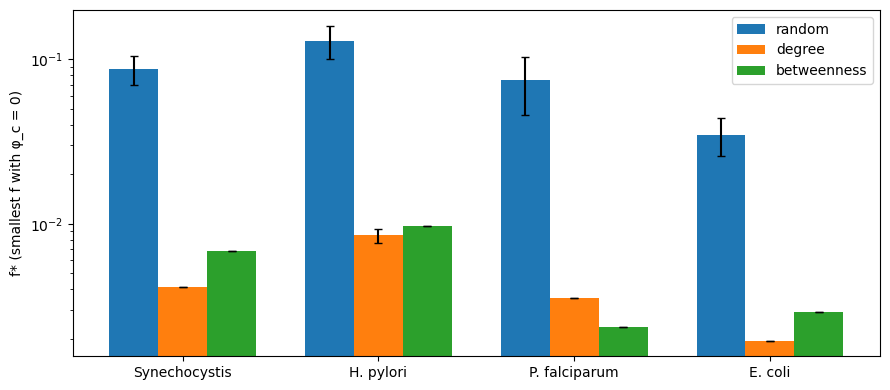

In [18]:
# critical budget, one group of bars per network
fig, ax = plt.subplots(figsize=(9, 4))
larghezza = 0.25
x = np.arange(len(reti))
for n, protocollo in enumerate(protocolli):
    t = [sintesi_45.loc[(nome, protocollo)] for nome in reti]
    ax.bar(x + (n - 1) * larghezza, [r["mean"] for r in t], larghezza, yerr=[r["std"] for r in t],
           capsize=3, label=protocollo)
ax.set_xticks(x, list(reti))
ax.set_ylabel("f* (smallest f with φ_c = 0)")
ax.set_yscale("log")
ax.legend()
plt.tight_layout()
plt.show()

### 4.6 Total robustness

`(1 − f)(1 − φ_c)`, the expected fraction of all the nodes that can fail before the giant component disappears
(notebook 04, section 1.3), with the critical budget `f*` of each protocol as a dashed vertical line.

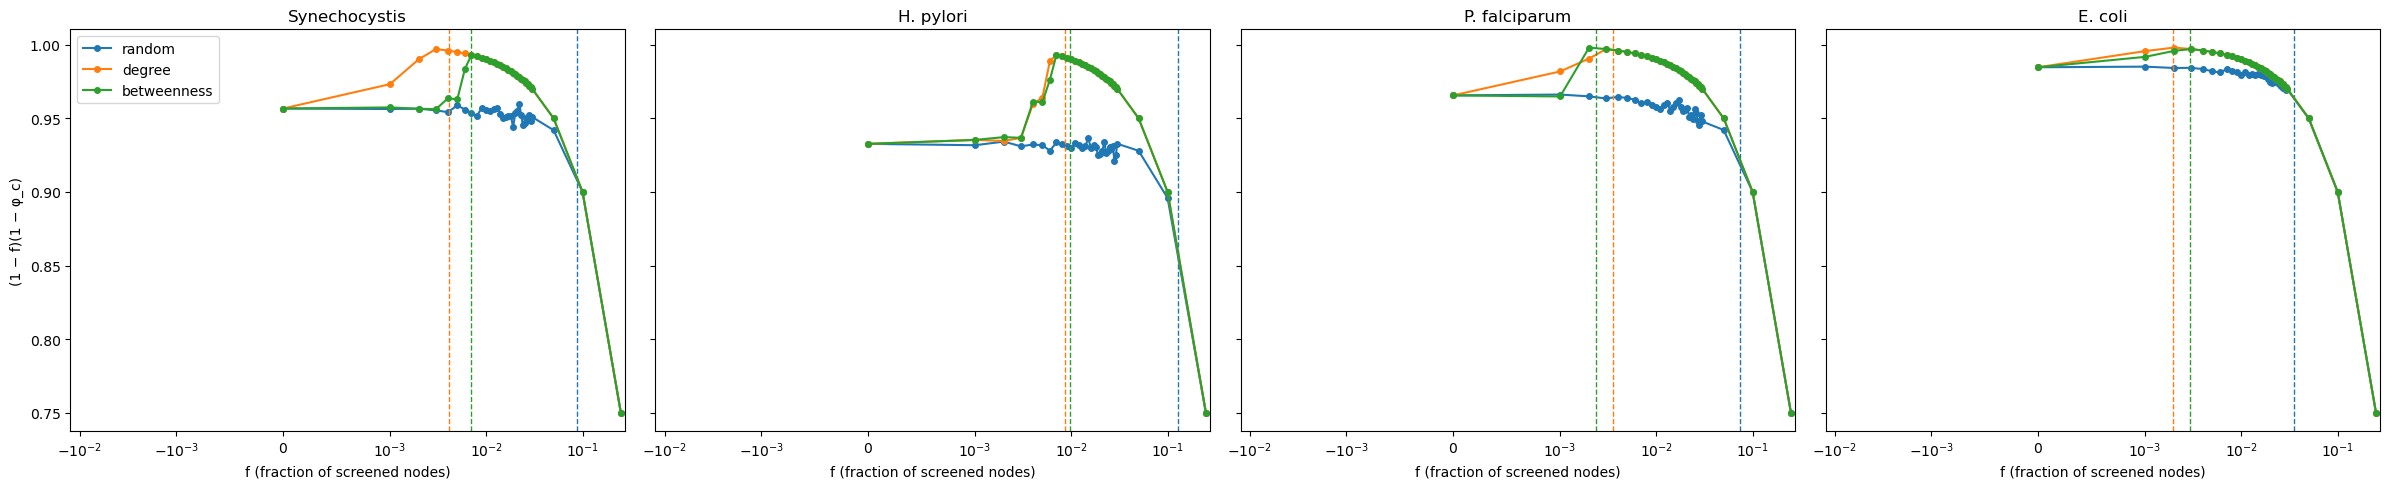

In [19]:
fig, assi = plt.subplots(1, len(reti), figsize=(24, 5), sharey=True)
for ax, nome in zip(assi, reti):
    for protocollo in protocolli:
        t = sintesi_44.loc[(nome, protocollo)]
        robustezza = (1 - t.index.to_numpy()) * (1 - t["mean"])
        linea, = ax.plot(t.index, robustezza, "o-", ms=4, label=protocollo)
        ax.axvline(sintesi_45.loc[(nome, protocollo), "mean"], color=linea.get_color(), ls="--", lw=1)
    ax.set_xscale("symlog", linthresh=0.001)
    ax.set_xlim(right=max(frazioni_44) * 1.1)
    ax.set_title(nome)
    ax.set_xlabel("f (fraction of screened nodes)")
assi[0].set_ylabel("(1 − f)(1 − φ_c)")
assi[0].legend()
plt.tight_layout()
plt.show()

### 4.7 Check against Monte Carlo

As in notebook 04, section 1.4: on the same draw of screened nodes, `φ_c` from the bisection (message passing) and
from the peak of the susceptibility `χ = (⟨S²⟩ − ⟨S⟩²)/⟨S⟩` (Radicchi, PRE 91, 010801 (2015), eqs. 2-3), with 100
Monte Carlo runs per `φ` for a single draw and 20 per draw when there are several draws (random screening).
`f` = 0, 1, 3, 10 and 30 screened nodes out of 1000, and 0.05, 0.10 as a reference. Grid of `φ`: step 0.0025 from
`φ_c MP − 0.1` up to `φ_c MP + 0.4` (the Monte Carlo peaks here can sit far above message passing, up to 0.38 in a
first run), step 0.05 elsewhere; a peak on the edge of the fine part is flagged. Cases with `φ_c` message passing
below 0.005 are marked `MP ≈ 0`. Mean and standard deviation over the draws. Saved in
`risultati/06/soglie_mc_fpiccole.csv` after each network.

In [20]:
frazioni_47 = [0.0, 0.001, 0.003, 0.01, 0.03, 0.05, 0.10]
num_runs_47 = 100          # one draw
num_runs_47_estr = 20      # per draw, when there are several draws (random)

file_47 = cartella_ris / "soglie_mc_fpiccole.csv"
soglie_mc = pd.read_csv(file_47) if file_47.exists() else pd.DataFrame(columns=["network"])

for nome, g in reti.items():
    if nome in set(soglie_mc["network"]):
        continue      # already computed: read from the csv
    t0 = time.time()
    G_mat, messaggi = G_reti[nome]
    righe = []
    for protocollo in protocolli:
        for frazione in frazioni_47:
            num_e = num_estrazioni(g, frazione, protocollo, betw[nome])
            runs_e = num_runs_47 if num_e == 1 else num_runs_47_estr
            for e in range(num_e):
                protetti = estrai_protetti(g, frazione, protocollo, rng, betw[nome])
                phi_c_mp = soglia_bisezione(g, G_mat, messaggi, protetti)

                # Monte Carlo threshold: peak of the susceptibility on the same draw, fine grid above phi_c MP
                phis_47 = griglia_phi(phi_c_mp + 0.15, larghezza=0.25, passo_fine=0.0025)
                runs = []
                for phi in phis_47:
                    phi_n = phi_ibrido(g, protetti, phi)      # built once per phi, the same for all the runs
                    runs.append([mc_1run_veloce(g, phi_n, rng, str_mc[nome]) for _ in range(runs_e)])
                runs = np.array(runs)
                media = runs.mean(axis=1)
                chi = runs.var(axis=1) / np.where(media > 0, media, np.nan)
                picco = np.nanargmax(chi)
                fine = np.diff(phis_47) < 0.01       # steps of the fine part
                bordo = picco == 0 or picco == len(phis_47) - 1 or not (fine[picco - 1] and fine[picco])

                righe.append({"network": nome, "protocol": protocollo, "f": frazione, "draw": e,
                              "phi_c MP": phi_c_mp, "phi_c MC": phis_47[picco], "peak on edge": bordo})
    soglie_mc = pd.concat([soglie_mc, pd.DataFrame(righe)], ignore_index=True)
    soglie_mc.to_csv(file_47, index=False)      # saved after each network
    print(f"{nome}: {time.time() - t0:.0f} s")

# mean and standard deviation over the draws (std empty with one draw)
sintesi_47 = soglie_mc.groupby(["network", "protocol", "f"], sort=False).agg(
    **{"phi_c MP": ("phi_c MP", "mean"), "std MP": ("phi_c MP", "std"),
       "phi_c MC": ("phi_c MC", "mean"), "std MC": ("phi_c MC", "std"),
       "draws": ("draw", "count"), "peaks on edge": ("peak on edge", "sum")}).reset_index()
sintesi_47["MP ≈ 0"] = sintesi_47["phi_c MP"] < 0.005
sintesi_47.round(4)

,network,protocol,f,phi_c MP,std MP,phi_c MC,std MC,draws,peaks on edge,MP ≈ 0
0,Synechocystis,random,0.000,0.0434,NaN,0.2025,NaN,1,0,False
1,Synechocystis,random,0.001,0.0419,0.0045,0.1894,0.0270,25,0,False
2,Synechocystis,random,0.003,0.0396,0.0062,0.1977,0.0234,14,0,False
3,Synechocystis,random,0.010,0.0394,0.0078,0.1932,0.0226,11,0,False
4,Synechocystis,random,0.030,0.0201,0.0125,0.1692,0.0154,10,0,False
...,...,...,...,...,...,...,...,...,...,...
79,E. coli,betweenness,0.003,0.0000,NaN,0.0975,NaN,1,0,True
80,E. coli,betweenness,0.010,0.0000,NaN,0.1500,NaN,1,0,True
81,E. coli,betweenness,0.030,0.0000,NaN,0.2025,NaN,1,0,True
82,E. coli,betweenness,0.050,0.0000,NaN,0.2025,NaN,1,0,True


**Bias of the Monte Carlo estimate.** At finite `N` the peak of `χ` sits above the true threshold
(notebook 02, section 1.6: on Erdős-Rényi with mean degree 3, 0.41 at `N = 1000` against 1/3, shrinking with
`N`). A protein network has a single size, so the shift cannot be measured by changing `N`. Reference: for each
protein network an Erdős-Rényi graph with the same `N` and `E` (few triangles, locally tree-like, where message
passing is close to exact), the same Monte Carlo estimate at `f = 0`, and the shift `MC − MP` there. The shift on the
protein network at `f = 0` is compared with it. The reference has the same size and mean degree but not the same
degree distribution.

In [21]:
phis_er = np.round(np.arange(0.0, 0.4001, 0.005), 3)    # the Erdos-Renyi thresholds are higher, about 1/<k>

righe = []
for nome, g in reti.items():
    er = nx.gnm_random_graph(g.number_of_nodes(), g.number_of_edges(), seed=1)
    str_er = struttura_mc(er)
    runs = np.array([[mc_1run_veloce(er, phi, rng, str_er) for _ in range(num_runs_47)] for phi in phis_er])
    media = runs.mean(axis=1)
    chi = runs.var(axis=1) / np.where(media > 0, media, np.nan)
    er_mc = phis_er[np.nanargmax(chi)]
    er_mp = 1 / lambda_max(matrice_G(er)[0])

    # protein network, f = 0: the three protocols are the same network, mean of the three Monte Carlo peaks
    t = sintesi_47[(sintesi_47["network"] == nome) & (sintesi_47["f"] == 0.0)]
    righe.append({"network": nome, "ER phi_c MP": er_mp, "ER phi_c MC": er_mc, "ER shift MC - MP": er_mc - er_mp,
                  "protein phi_c MP": t["phi_c MP"].mean(), "protein phi_c MC": t["phi_c MC"].mean(),
                  "protein shift MC - MP": t["phi_c MC"].mean() - t["phi_c MP"].mean()})
bias_mc = pd.DataFrame(righe).set_index("network")
bias_mc.round(4)

,ER phi_c MP,ER phi_c MC,ER shift MC - MP,protein phi_c MP,protein phi_c MC,protein shift MC - MP
network,,,,,,
Synechocystis,0.1784,0.215,0.0366,0.0434,0.2042,0.1608
H. pylori,0.1879,0.215,0.0271,0.0674,0.2025,0.1351
P. falciparum,0.1834,0.210,0.0266,0.0345,0.1575,0.1230
E. coli,0.0760,0.080,0.0040,0.0154,0.0750,0.0596


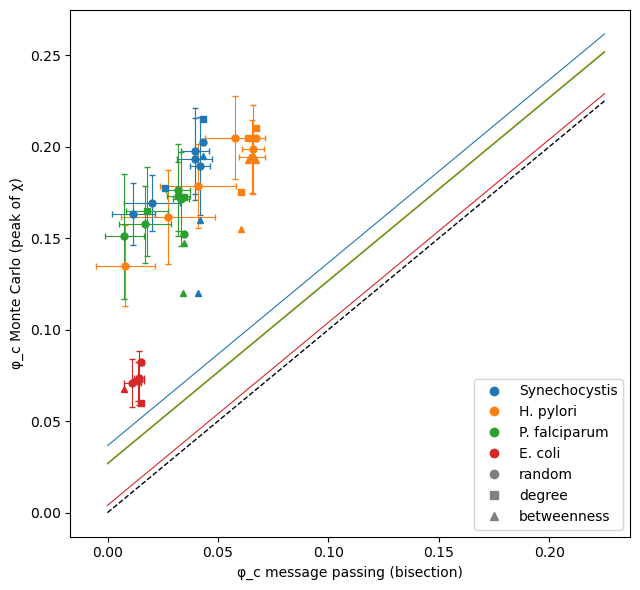

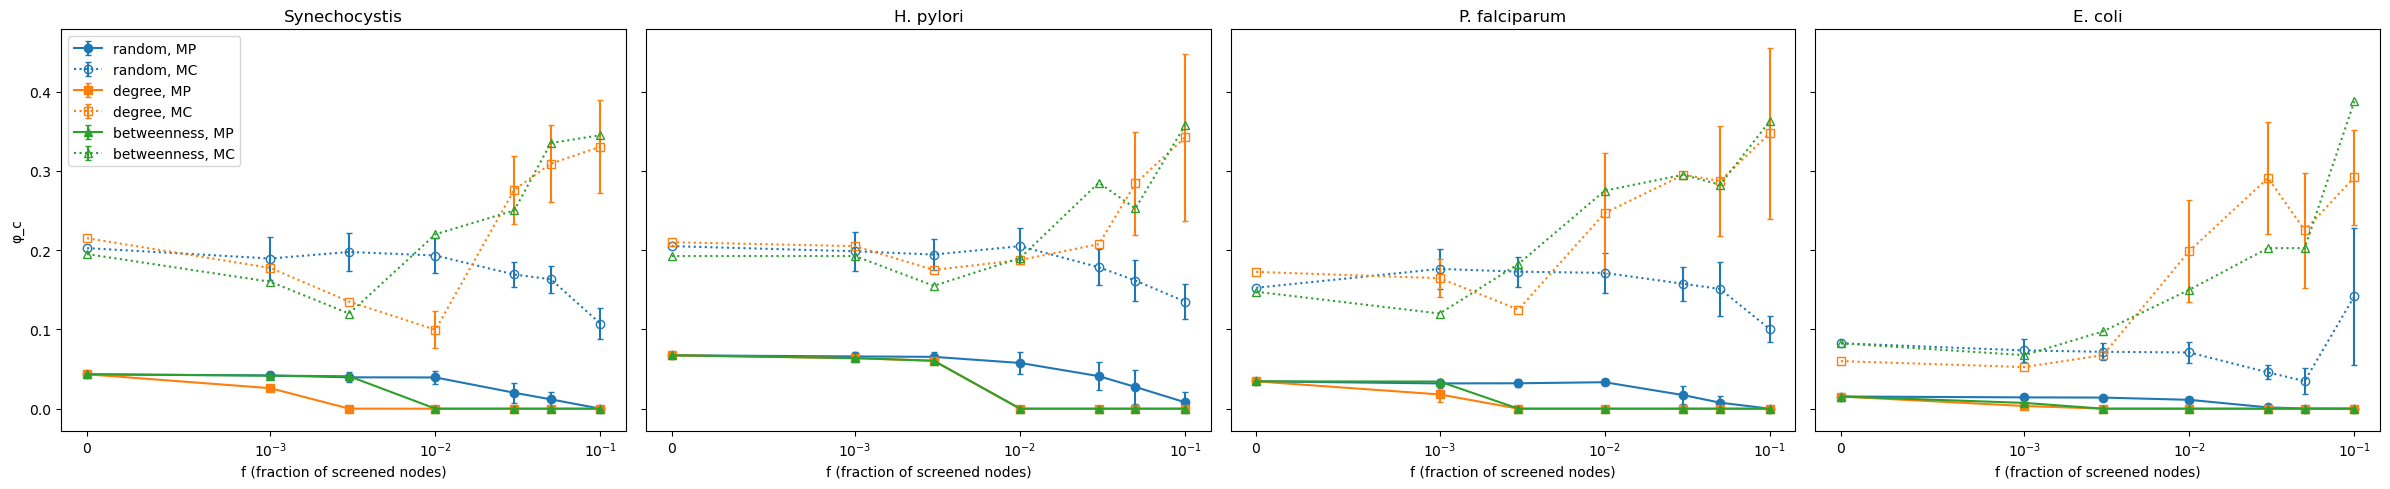

In [22]:
# MC threshold against MP threshold (cases MP ≈ 0 left out): on the dashed line they agree;
# solid lines: MC = MP + the shift of the Erdos-Renyi reference of the same network;
# error bars: standard deviation over the draws (random screening)
marker = {"random": "o", "degree": "s", "betweenness": "^"}
colore = dict(zip(reti, ["tab:blue", "tab:orange", "tab:green", "tab:red"]))
validi = sintesi_47[~sintesi_47["MP ≈ 0"]]

fig, ax = plt.subplots(figsize=(6.5, 6))
for (nome, protocollo), t in validi.groupby(["network", "protocol"], sort=False):
    ax.errorbar(t["phi_c MP"], t["phi_c MC"], xerr=t["std MP"], yerr=t["std MC"], fmt=marker[protocollo],
                color=colore[nome], ms=5, capsize=2, lw=0.8)
lim = [0, max(validi["phi_c MC"].max(), validi["phi_c MP"].max()) + 0.01]
ax.plot(lim, lim, "k--", lw=1)
for nome in reti:
    ax.plot(lim, [x + bias_mc.loc[nome, "ER shift MC - MP"] for x in lim], "-", color=colore[nome], lw=0.8)
ax.set_xlabel("φ_c message passing (bisection)")
ax.set_ylabel("φ_c Monte Carlo (peak of χ)")
for nome in reti:
    ax.plot([], [], "o", color=colore[nome], label=nome)
for protocollo in protocolli:
    ax.plot([], [], marker[protocollo], color="gray", label=protocollo)
ax.legend()
plt.tight_layout()
plt.show()

# both thresholds against f, one panel per network: solid message passing, dotted Monte Carlo
fig, assi = plt.subplots(1, len(reti), figsize=(24, 5), sharey=True)
for ax, nome in zip(assi, reti):
    for n, protocollo in enumerate(protocolli):
        t = sintesi_47[(sintesi_47["network"] == nome) & (sintesi_47["protocol"] == protocollo)]
        ax.errorbar(t["f"], t["phi_c MP"], yerr=t["std MP"], fmt=marker[protocollo] + "-", color=f"C{n}",
                    capsize=2, label=f"{protocollo}, MP")
        ax.errorbar(t["f"], t["phi_c MC"], yerr=t["std MC"], fmt=marker[protocollo] + ":", color=f"C{n}",
                    mfc="none", capsize=2, label=f"{protocollo}, MC")
    ax.set_xscale("symlog", linthresh=0.001)
    ax.set_title(nome)
    ax.set_xlabel("f (fraction of screened nodes)")
assi[0].set_ylabel("φ_c")
assi[0].legend()
plt.tight_layout()
plt.show()

#### Comment on section 4

At f = 0 the bisection gives back 1/λ_max (0.04337, 0.06735, 0.03445 against 0.03447, and 0.01535). With degree and betweenness screening φ_c reaches 0 at f = 0.01 or earlier on all four networks; with random screening only at f = 0.10 (Synechocystis, P. falciparum), f = 0.25 (H. pylori) and f = 0.05 (E. coli). The critical budget f* is 0.0041, 0.0085, 0.0036 and 0.0020 for degree, 0.0069, 0.0097, 0.0024 and 0.0029 for betweenness, 0.087, 0.130, 0.074 and 0.035 for random (Synechocystis, H. pylori, P. falciparum, E. coli): degree needs slightly fewer nodes than betweenness on three networks, betweenness on P. falciparum, and the better of the two needs 15 to 30 times fewer nodes than random screening. (Synechocystis and P. falciparum, degree, f = 0.003: φ_c shows 0.0000 in the table of 4.4 although f* is above 0.003 (0.0041 and 0.0036); it should be a positive value below 5e-5 hidden by the rounding, to check.)

Monte Carlo check: at f = 0 the χ peak is at 0.20 (Synechocystis, H. pylori), 0.16 (P. falciparum) and 0.075 (E. coli), against 0.043, 0.067, 0.034 and 0.015 from message passing, a shift of 0.161, 0.135, 0.123 and 0.060. On Erdos-Renyi networks with the same N and E the shift is 0.037, 0.027, 0.027 and 0.004: on the proteins it is 4 to 15 times larger. In the cases with MP ≈ 0 the Monte Carlo still finds a peak between 0.035 and 0.39.

## 5. Curves S(φ) for each protocol

As in notebook 04, section 2. `f` = 0, 1, 3, 10 and 30 screened nodes out of 1000, and 0.05, 0.10 as a reference;
draws as in section 4.4, each kept fixed for all the values of `φ` (quenched). Grid of `φ`: step 0.01 within ±0.1 of
`φ_c` (mean over the draws, widened by their spread), step 0.05 elsewhere. Message passing (lines) with the compiled
solver and warm start from high to low `φ` (`curva_mp`); Monte Carlo with 50 runs per value of `φ` (20 per draw when
there are several draws): mean (dots), **shaded band** = standard error of the mean, **error bars** = ±1 standard
deviation of the runs; with several draws both are taken within the draws. Linear `φ` axis. First figure: the whole curve for three
values of `f` (0.001, 0.003, 0.03), means and bars only, vertical dotted lines at `φ_c` from the bisection. Then one
figure for each `f`, zoom on `φ ≤ 0.4`, with the band and with both thresholds: `φ_c` from the bisection (dotted) and
from the peak of `χ` of section 4.7 (dashed), computed on the same draws.
`S` is divided by all the `N` nodes. Saved in `risultati/06/curve_protocolli_fpiccole.csv` after each network.

In [23]:
frazioni_5 = [0.0, 0.001, 0.003, 0.01, 0.03, 0.05, 0.10]
num_runs_5 = 50            # one draw
num_runs_5_estr = 20       # per draw, when there are several draws (random)

file_5 = cartella_ris / "curve_protocolli_fpiccole.csv"
curve_prot = pd.read_csv(file_5) if file_5.exists() else pd.DataFrame(columns=["network"])

for nome, g in reti.items():
    if nome in set(curve_prot["network"]):
        continue      # already computed: read from the csv
    t0 = time.time()
    G_mat, messaggi = G_reti[nome]
    righe = []
    for protocollo in protocolli:
        for frazione in frazioni_5:
            num_e = num_estrazioni(g, frazione, protocollo, betw[nome])
            runs_e = num_runs_5 if num_e == 1 else num_runs_5_estr

            # first all the draws and their phi_c (cheap), then one common grid for the case
            estrazioni = [estrai_protetti(g, frazione, protocollo, rng, betw[nome]) for _ in range(num_e)]
            soglie = [soglia_bisezione(g, G_mat, messaggi, p) for p in estrazioni]
            phis_5 = griglia_phi(np.mean(soglie), larghezza=0.1 + (max(soglie) - min(soglie)) / 2)

            for e, (protetti, phi_c) in enumerate(zip(estrazioni, soglie)):
                S_mp = curva_mp(g, phis_5, protetti, str_mp[nome])      # warm start from high to low phi
                for k, phi in enumerate(phis_5):
                    phi_n = phi_ibrido(g, protetti, phi)
                    runs = [mc_1run_veloce(g, phi_n, rng, str_mc[nome]) for _ in range(runs_e)]
                    righe.append({"network": nome, "protocol": protocollo, "f": frazione, "draw": e, "phi": phi,
                                  "S MP": S_mp[k], "S MC": np.mean(runs), "S MC std": np.std(runs),
                                  "runs": runs_e, "phi_c": phi_c})
    curve_prot = pd.concat([curve_prot, pd.DataFrame(righe)], ignore_index=True)
    curve_prot.to_csv(file_5, index=False)      # saved after each network
    print(f"{nome}: {time.time() - t0:.0f} s")

# one curve per case: mean over the draws; std pooled within the draws; standard error over all the runs
curve_5 = curve_prot.groupby(["network", "protocol", "f", "phi"], sort=False).apply(
    lambda t: pd.Series({"S MP": t["S MP"].mean(), "S MC": t["S MC"].mean(),
                         "std": np.sqrt(np.mean(t["S MC std"] ** 2)),
                         "sem": np.sqrt(np.mean(t["S MC std"] ** 2)) / np.sqrt(t["runs"].sum()),
                         "phi_c": t["phi_c"].mean()}), include_groups=False).reset_index()

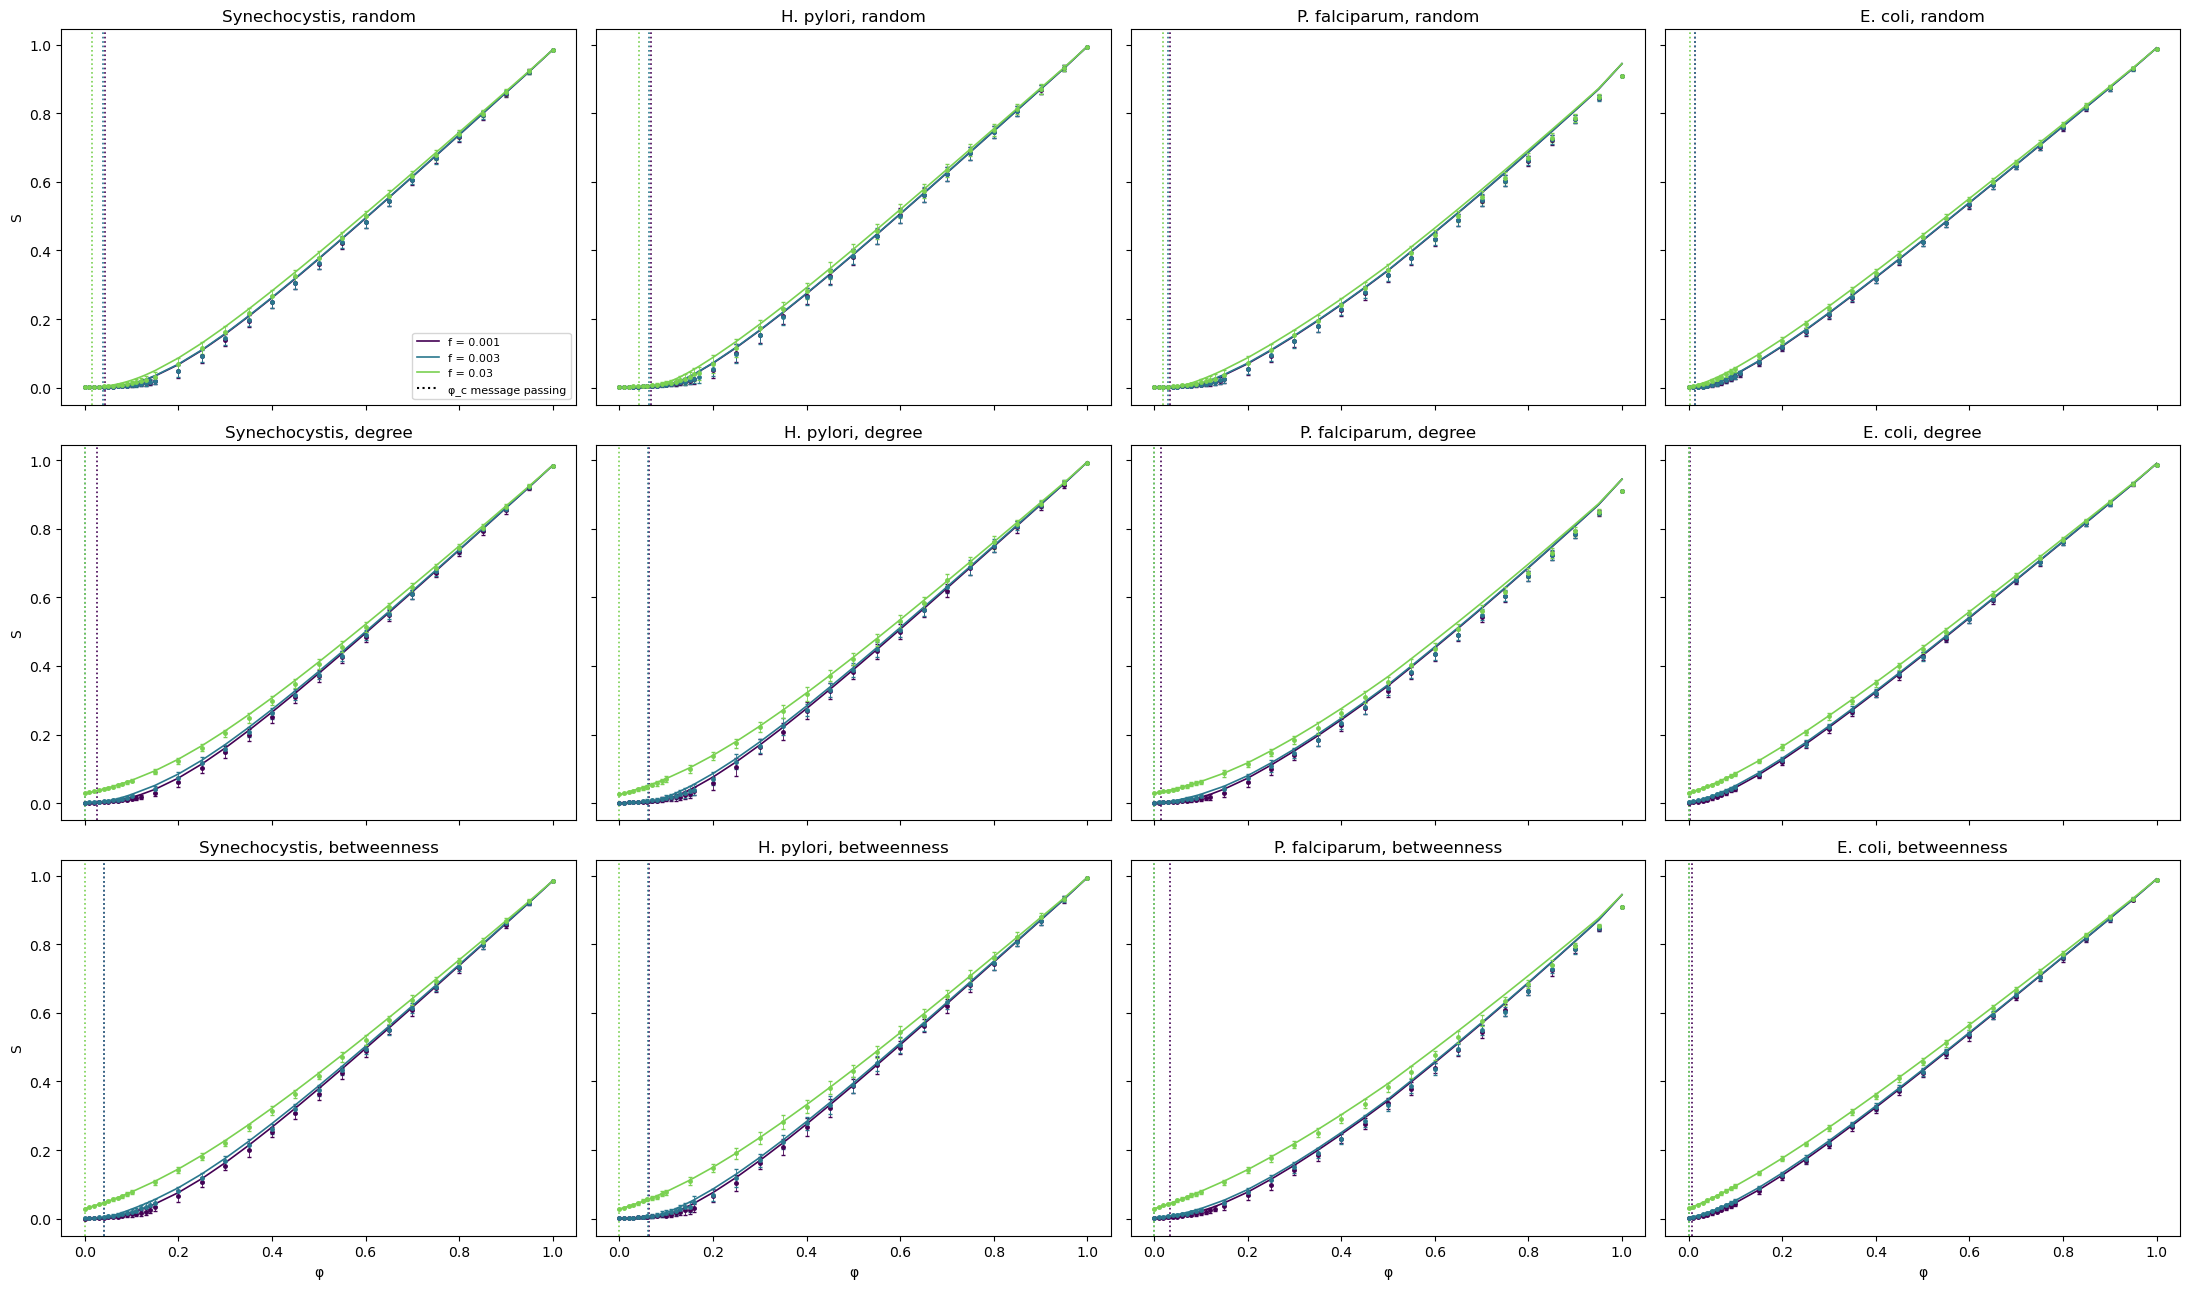

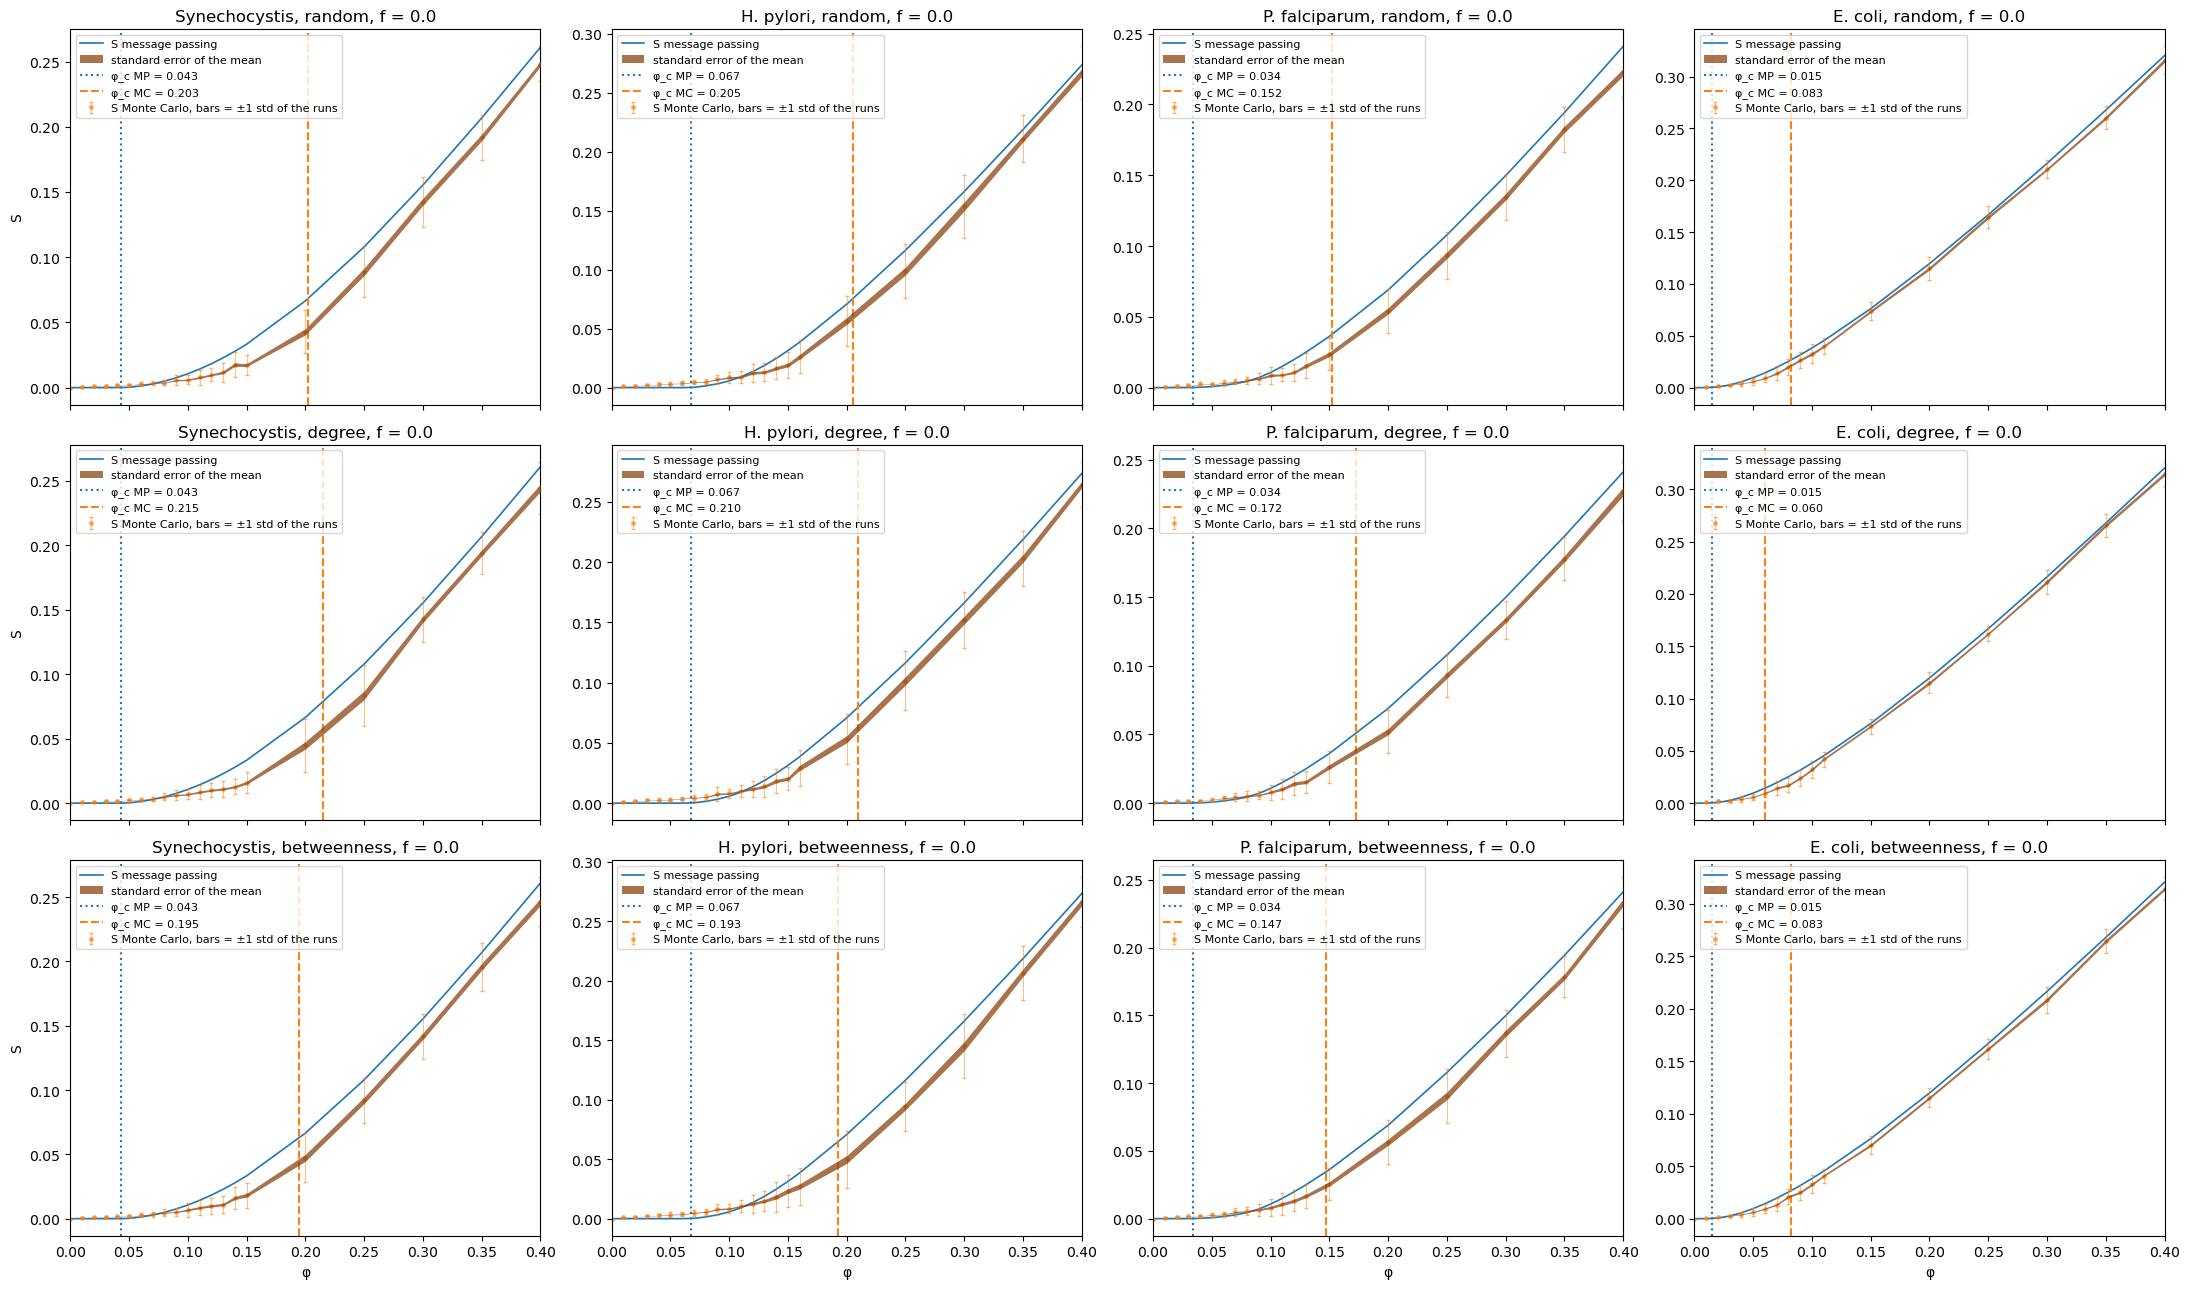

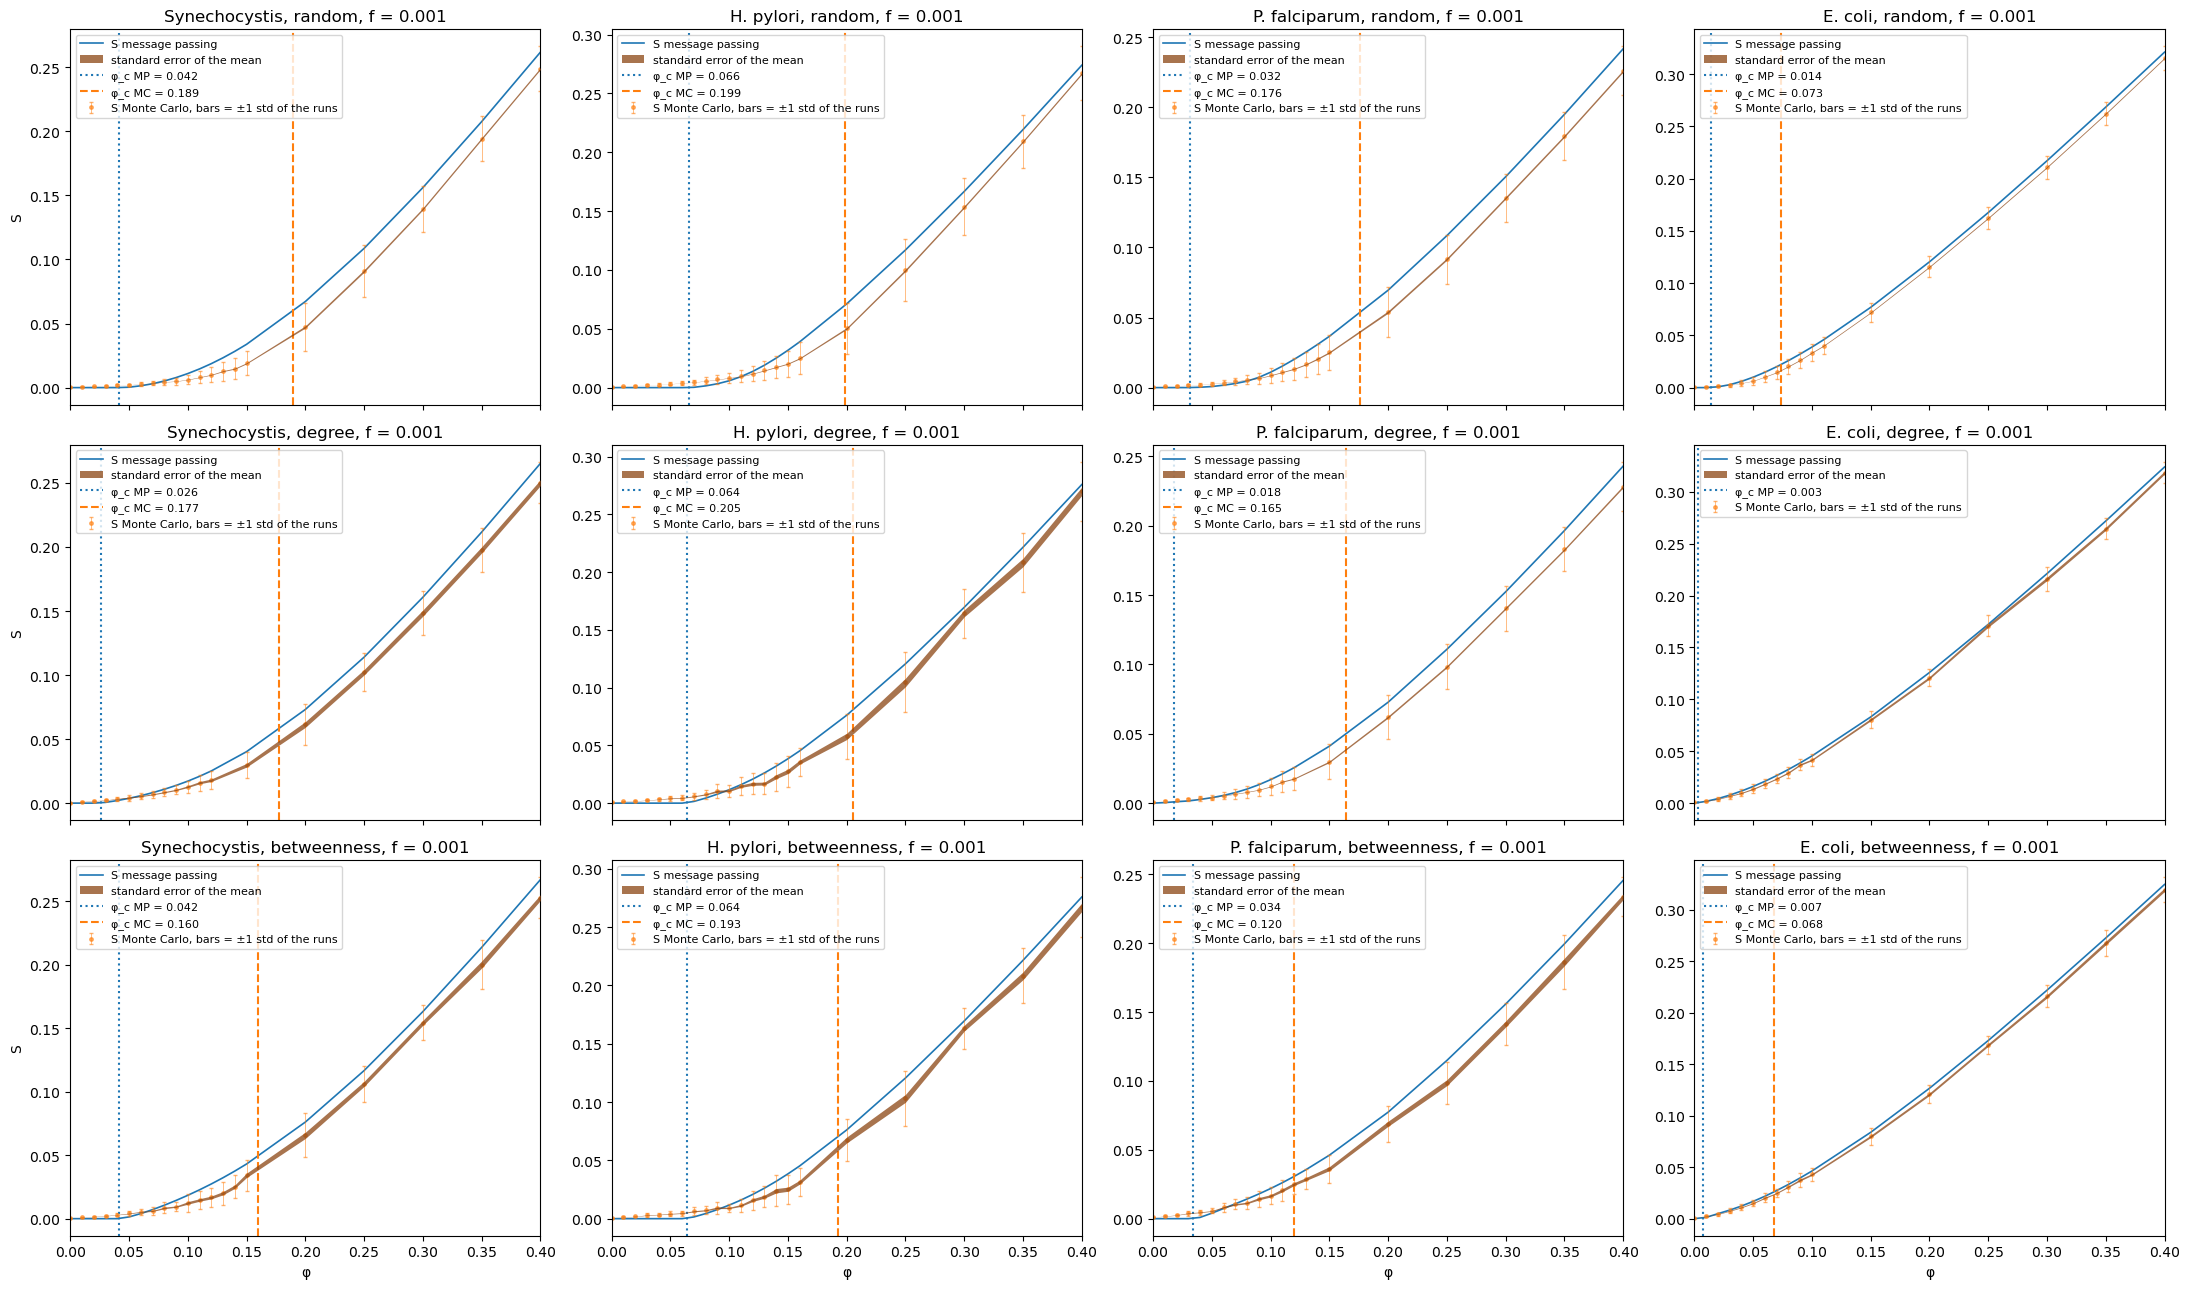

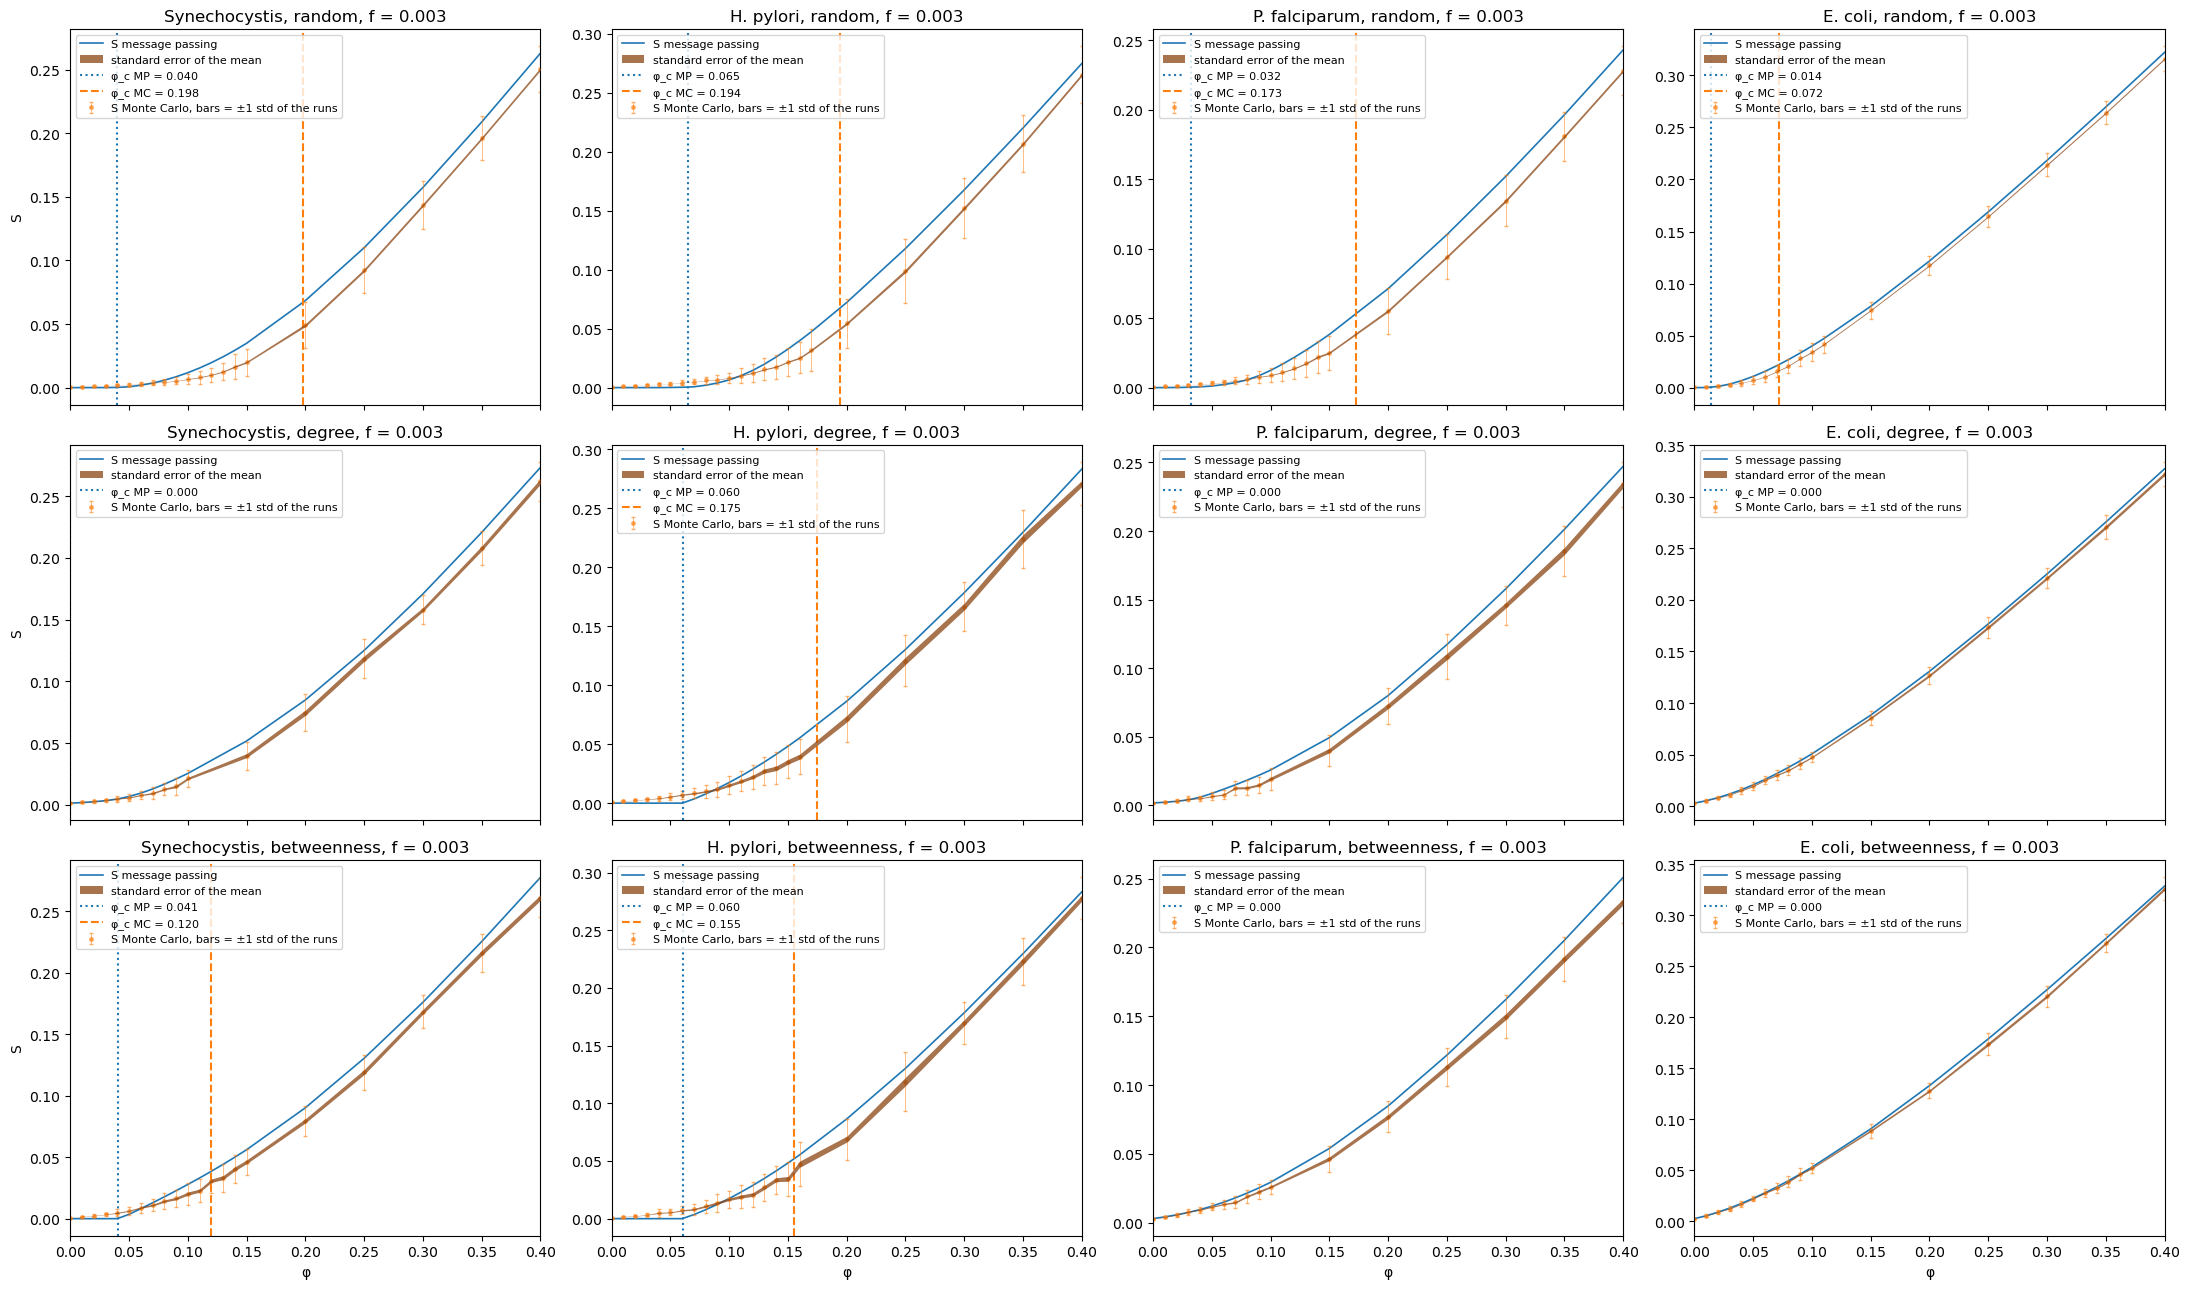

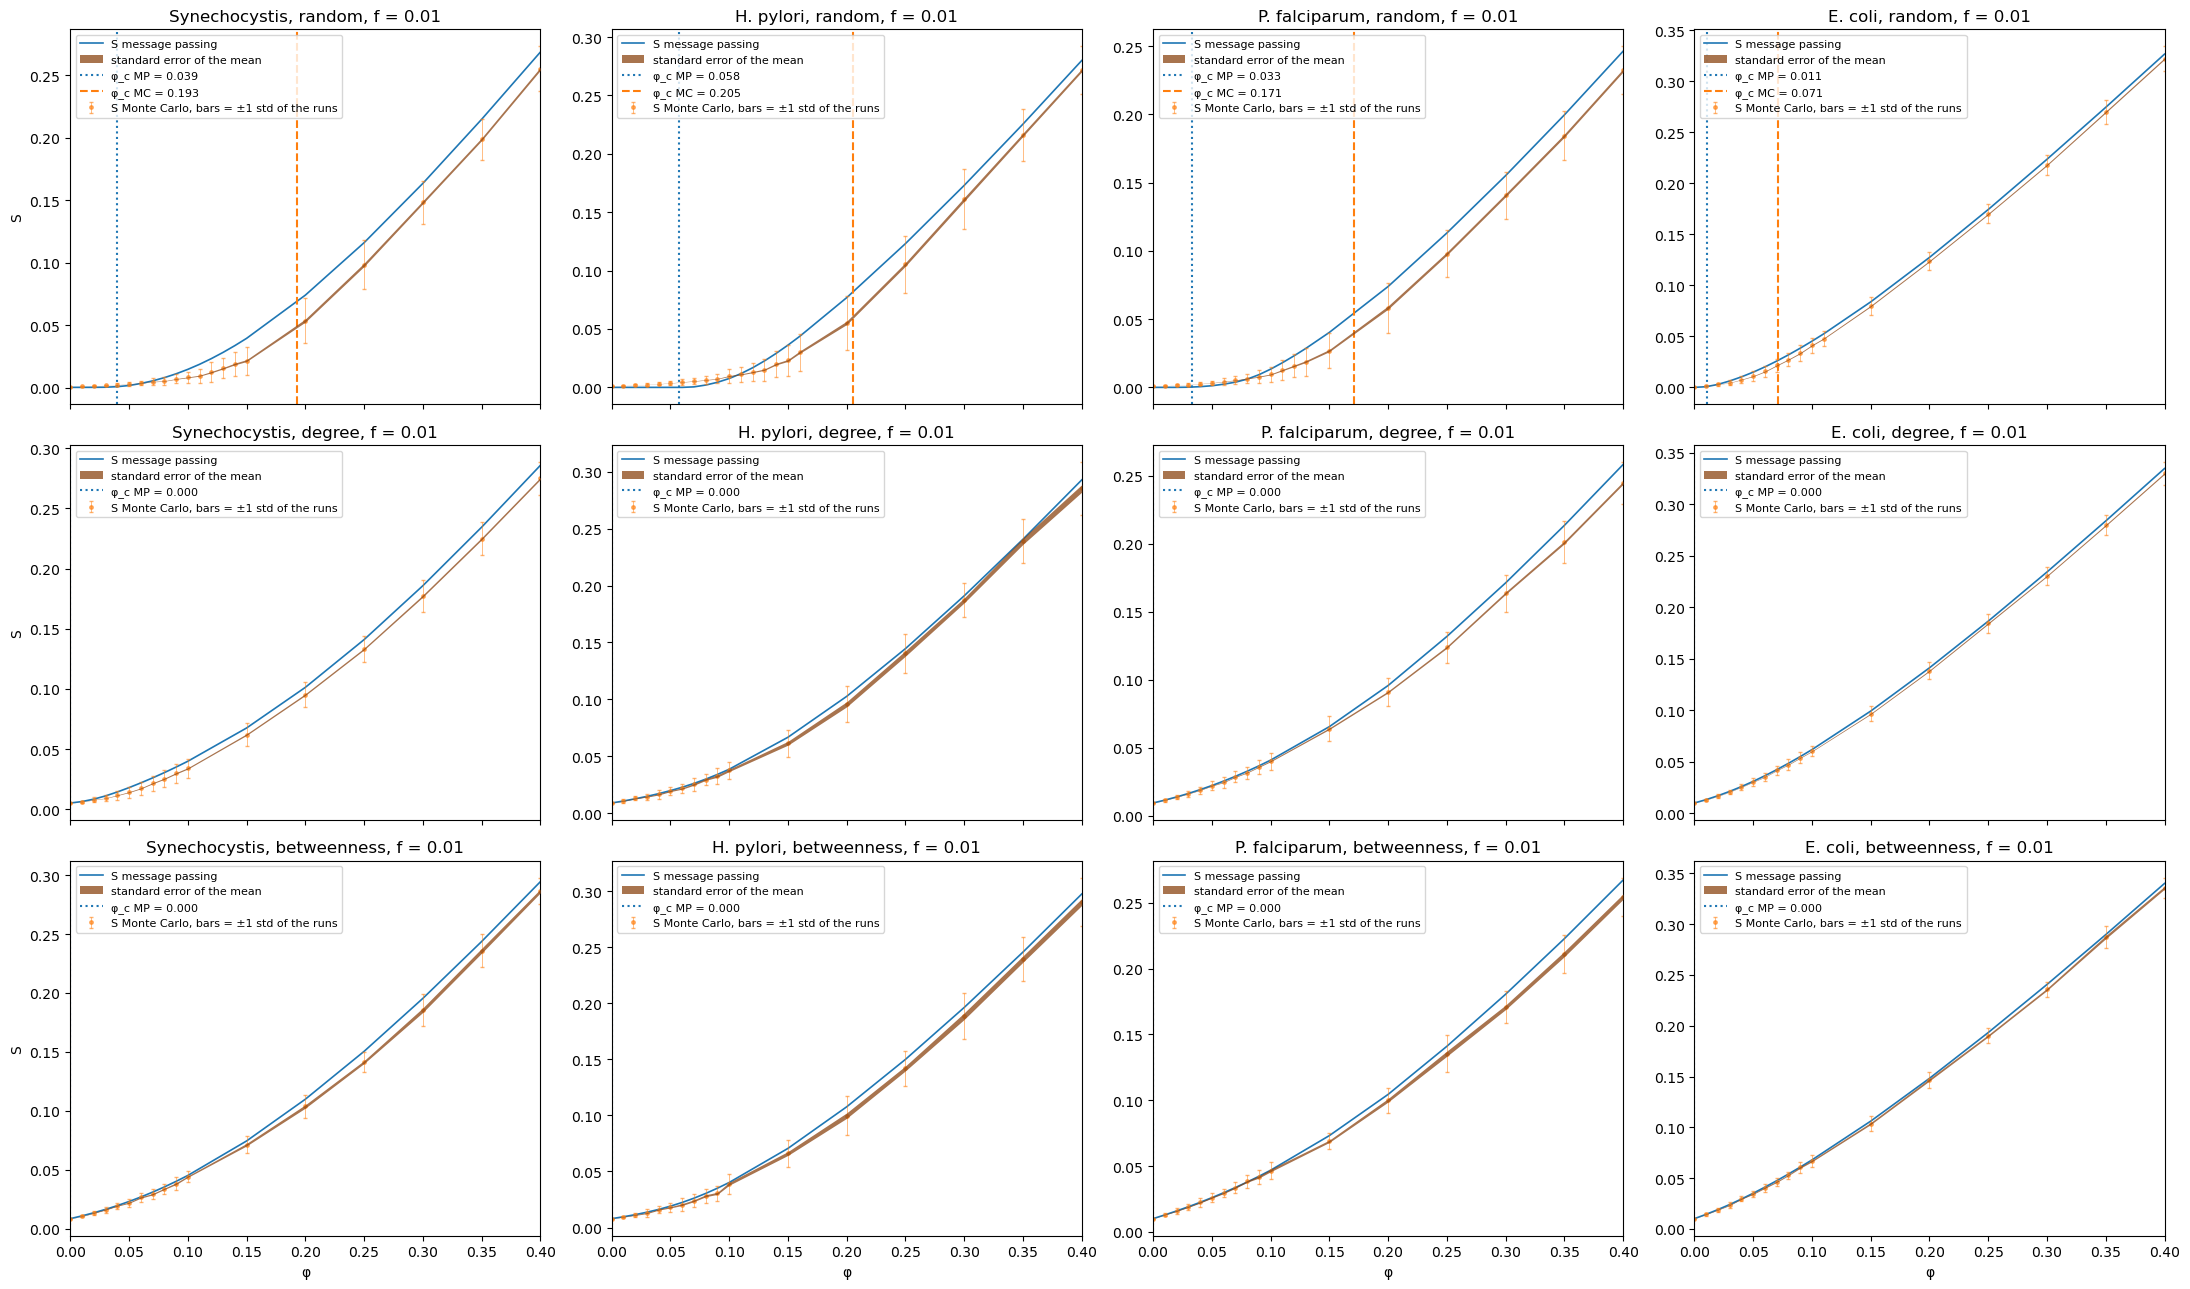

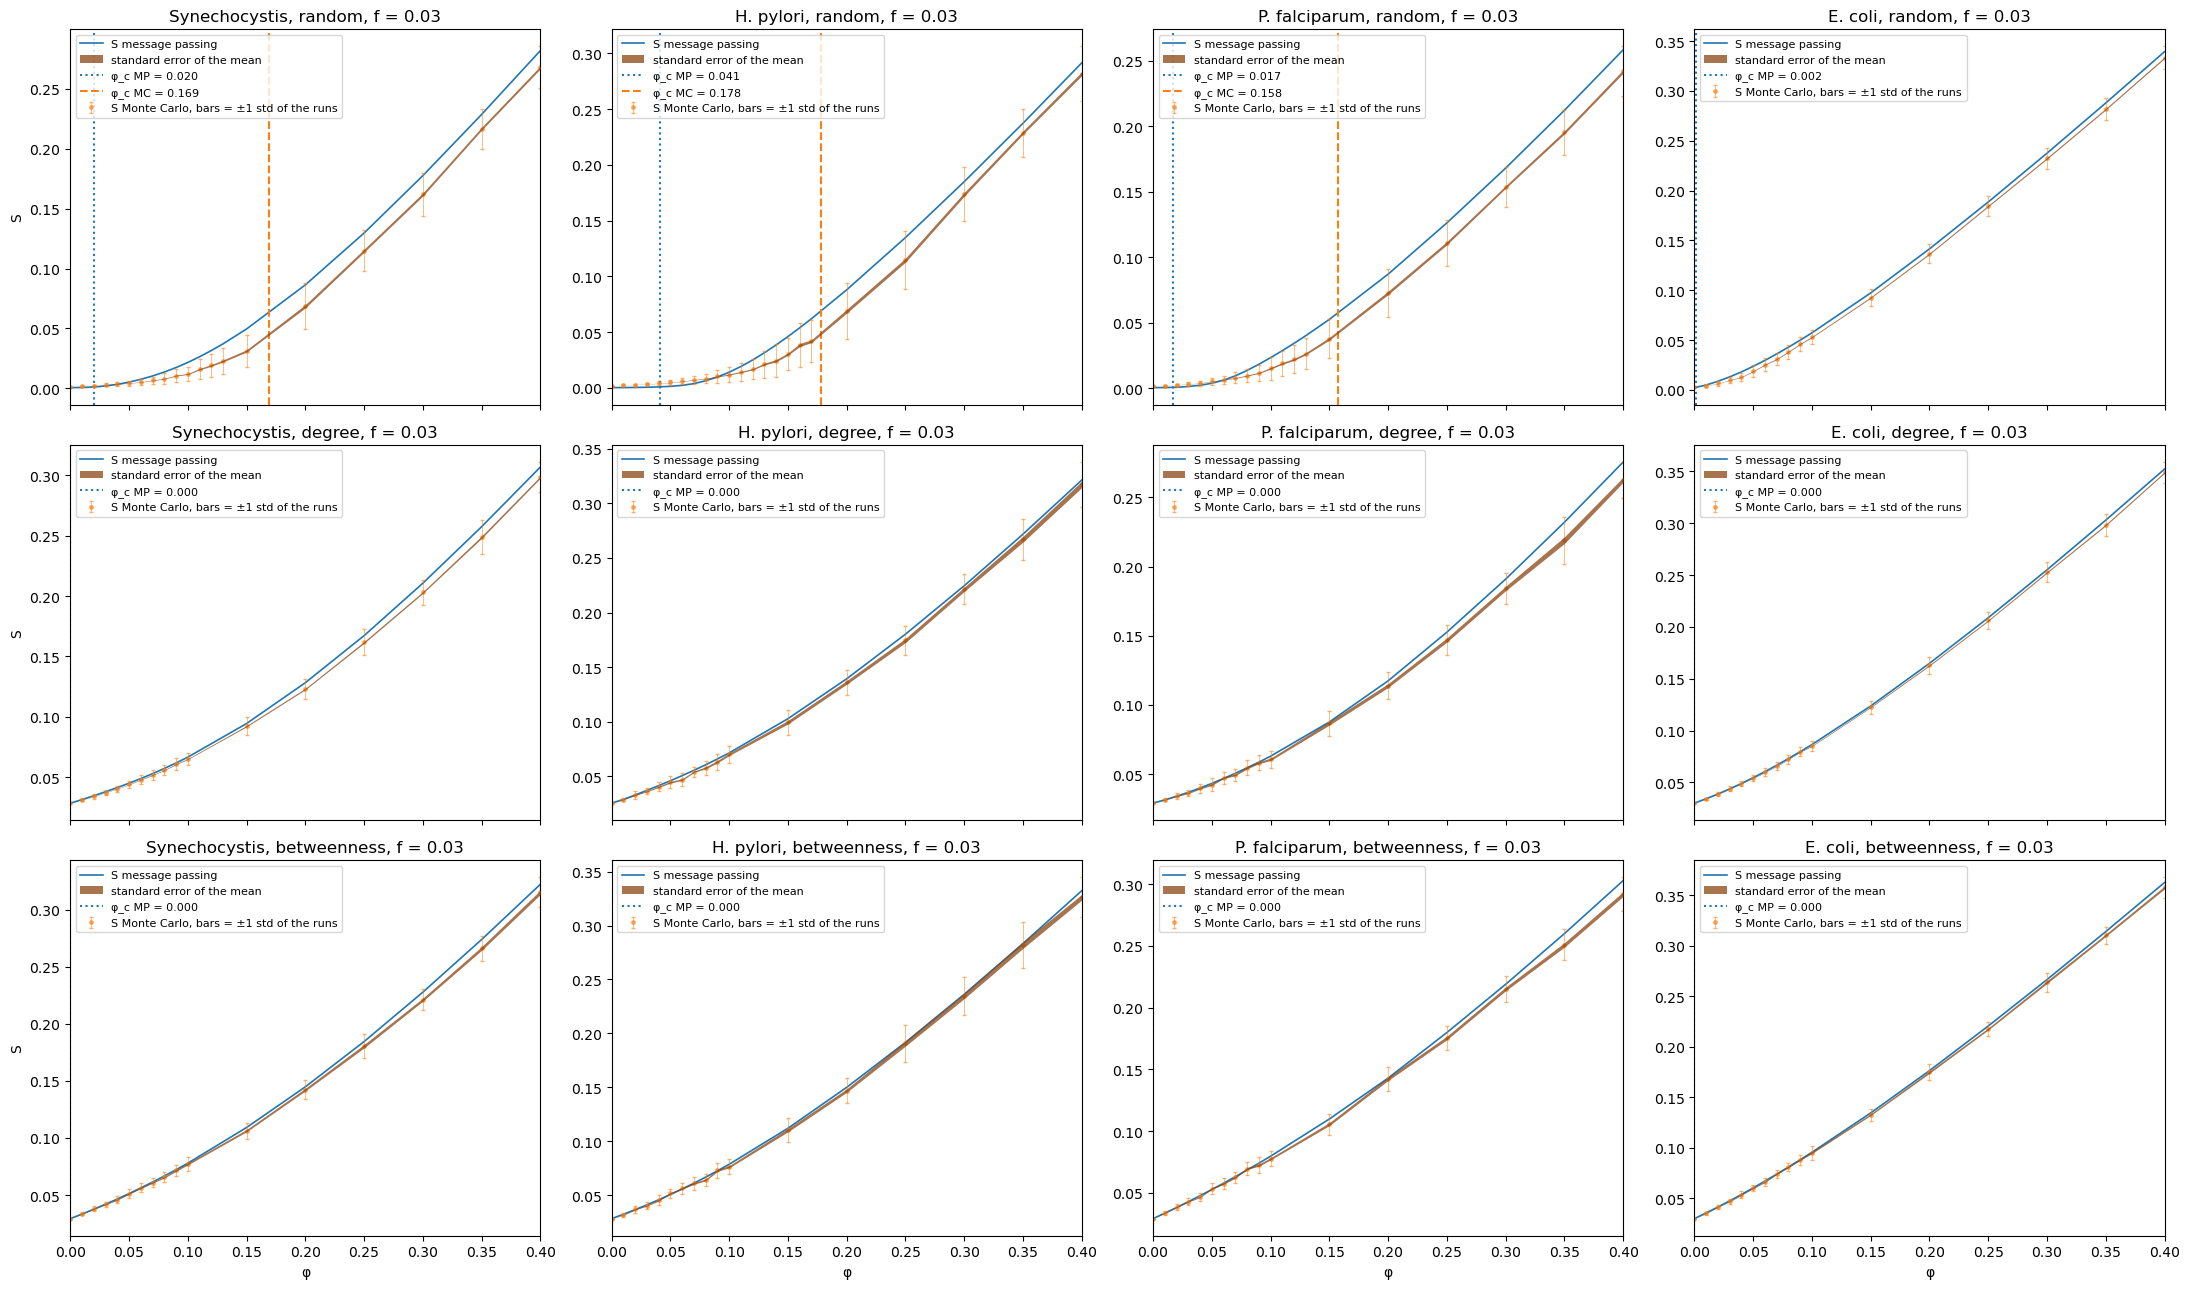

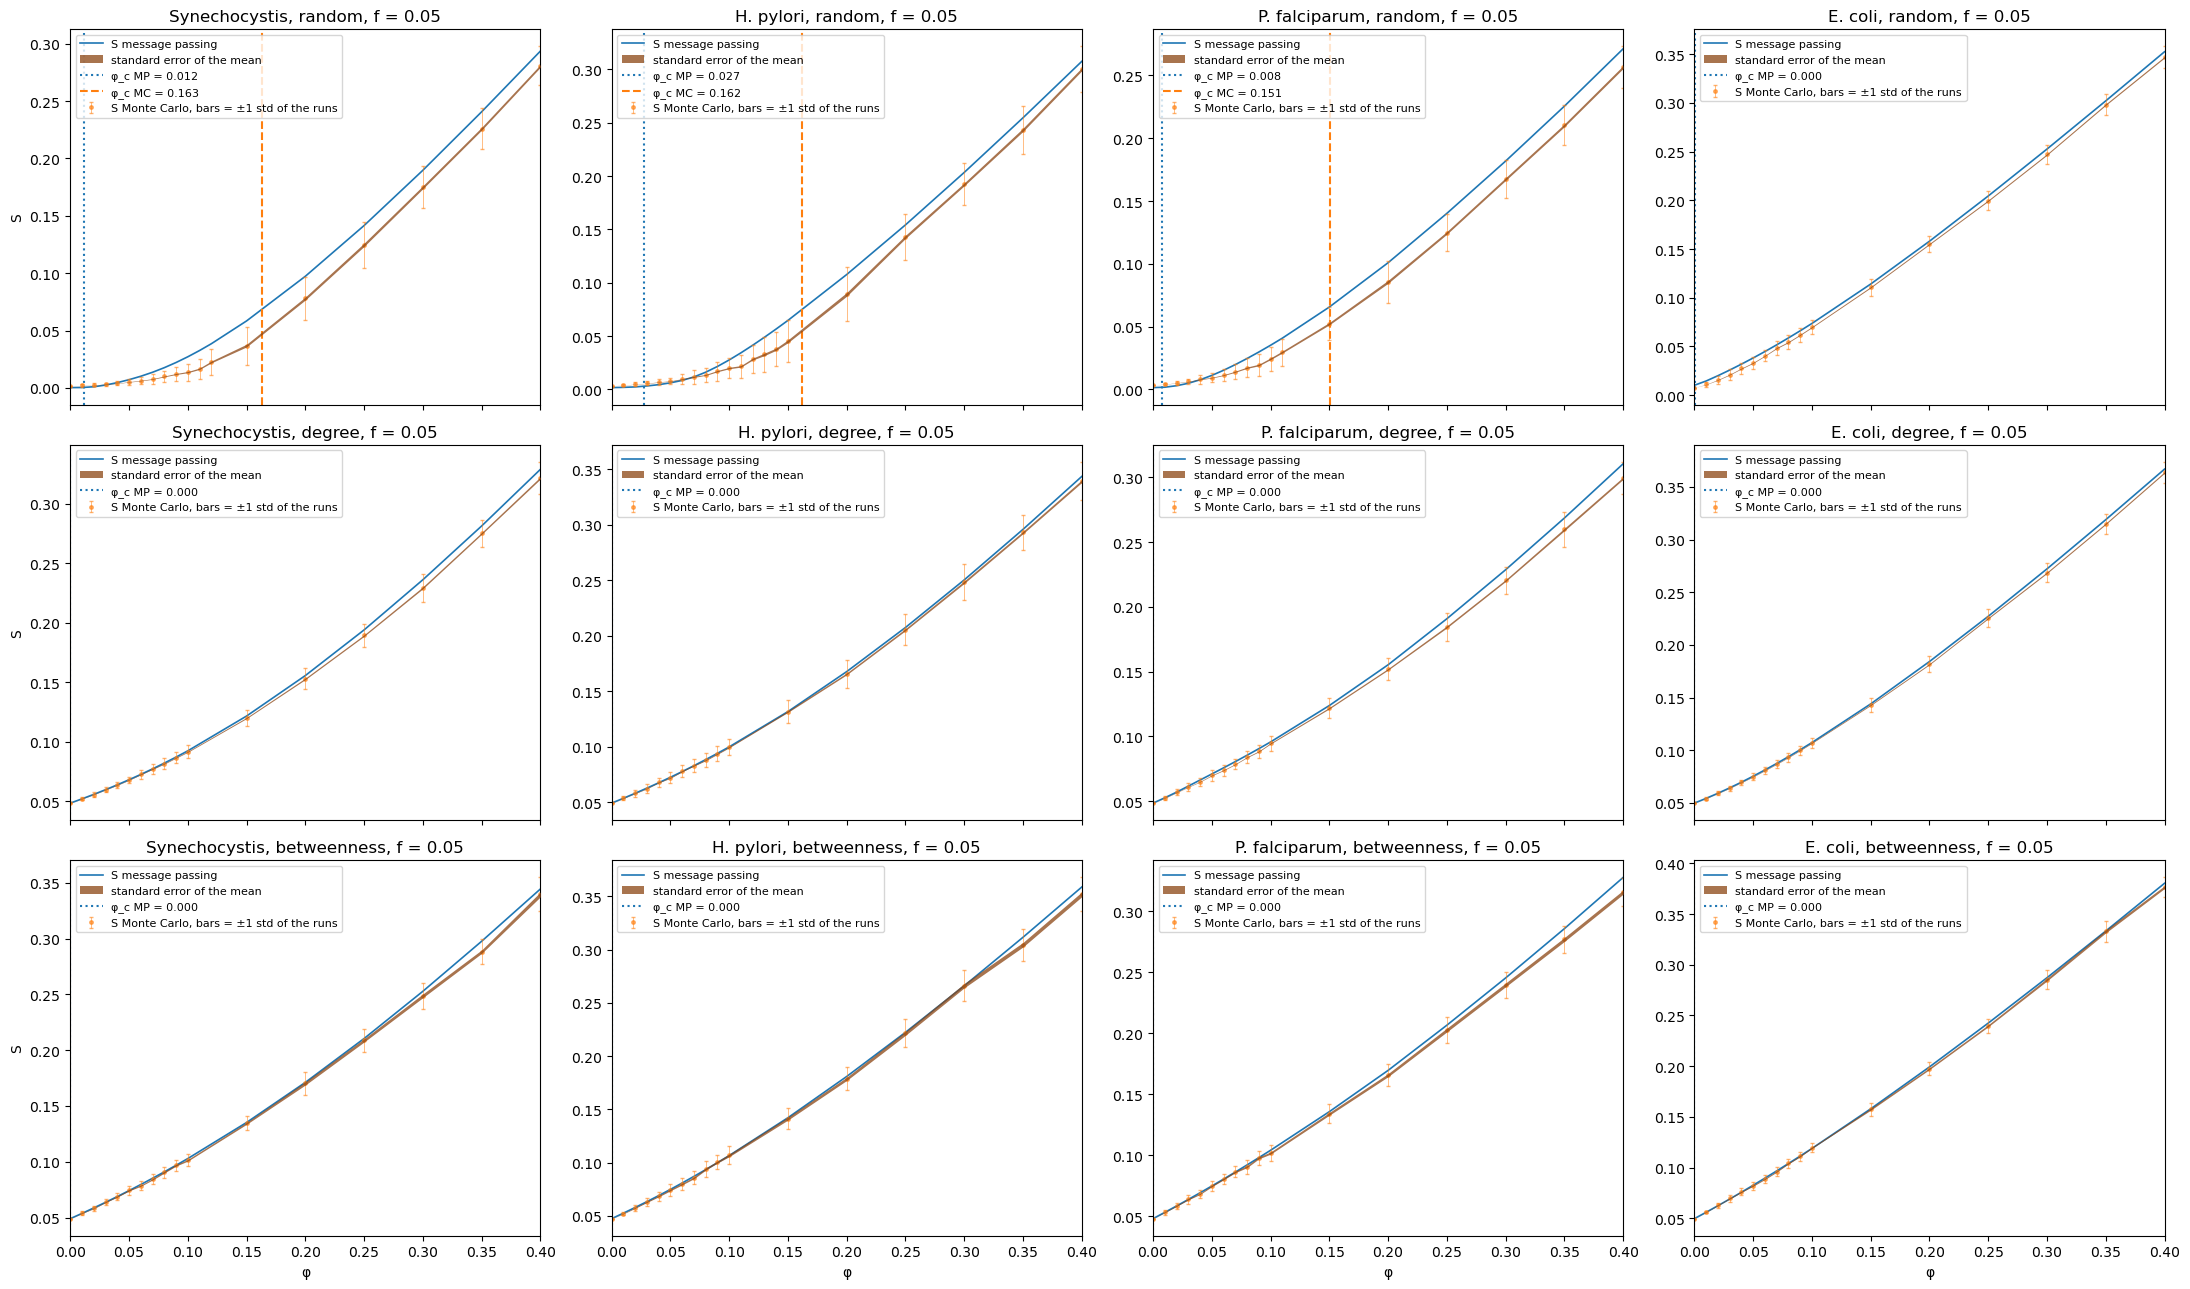

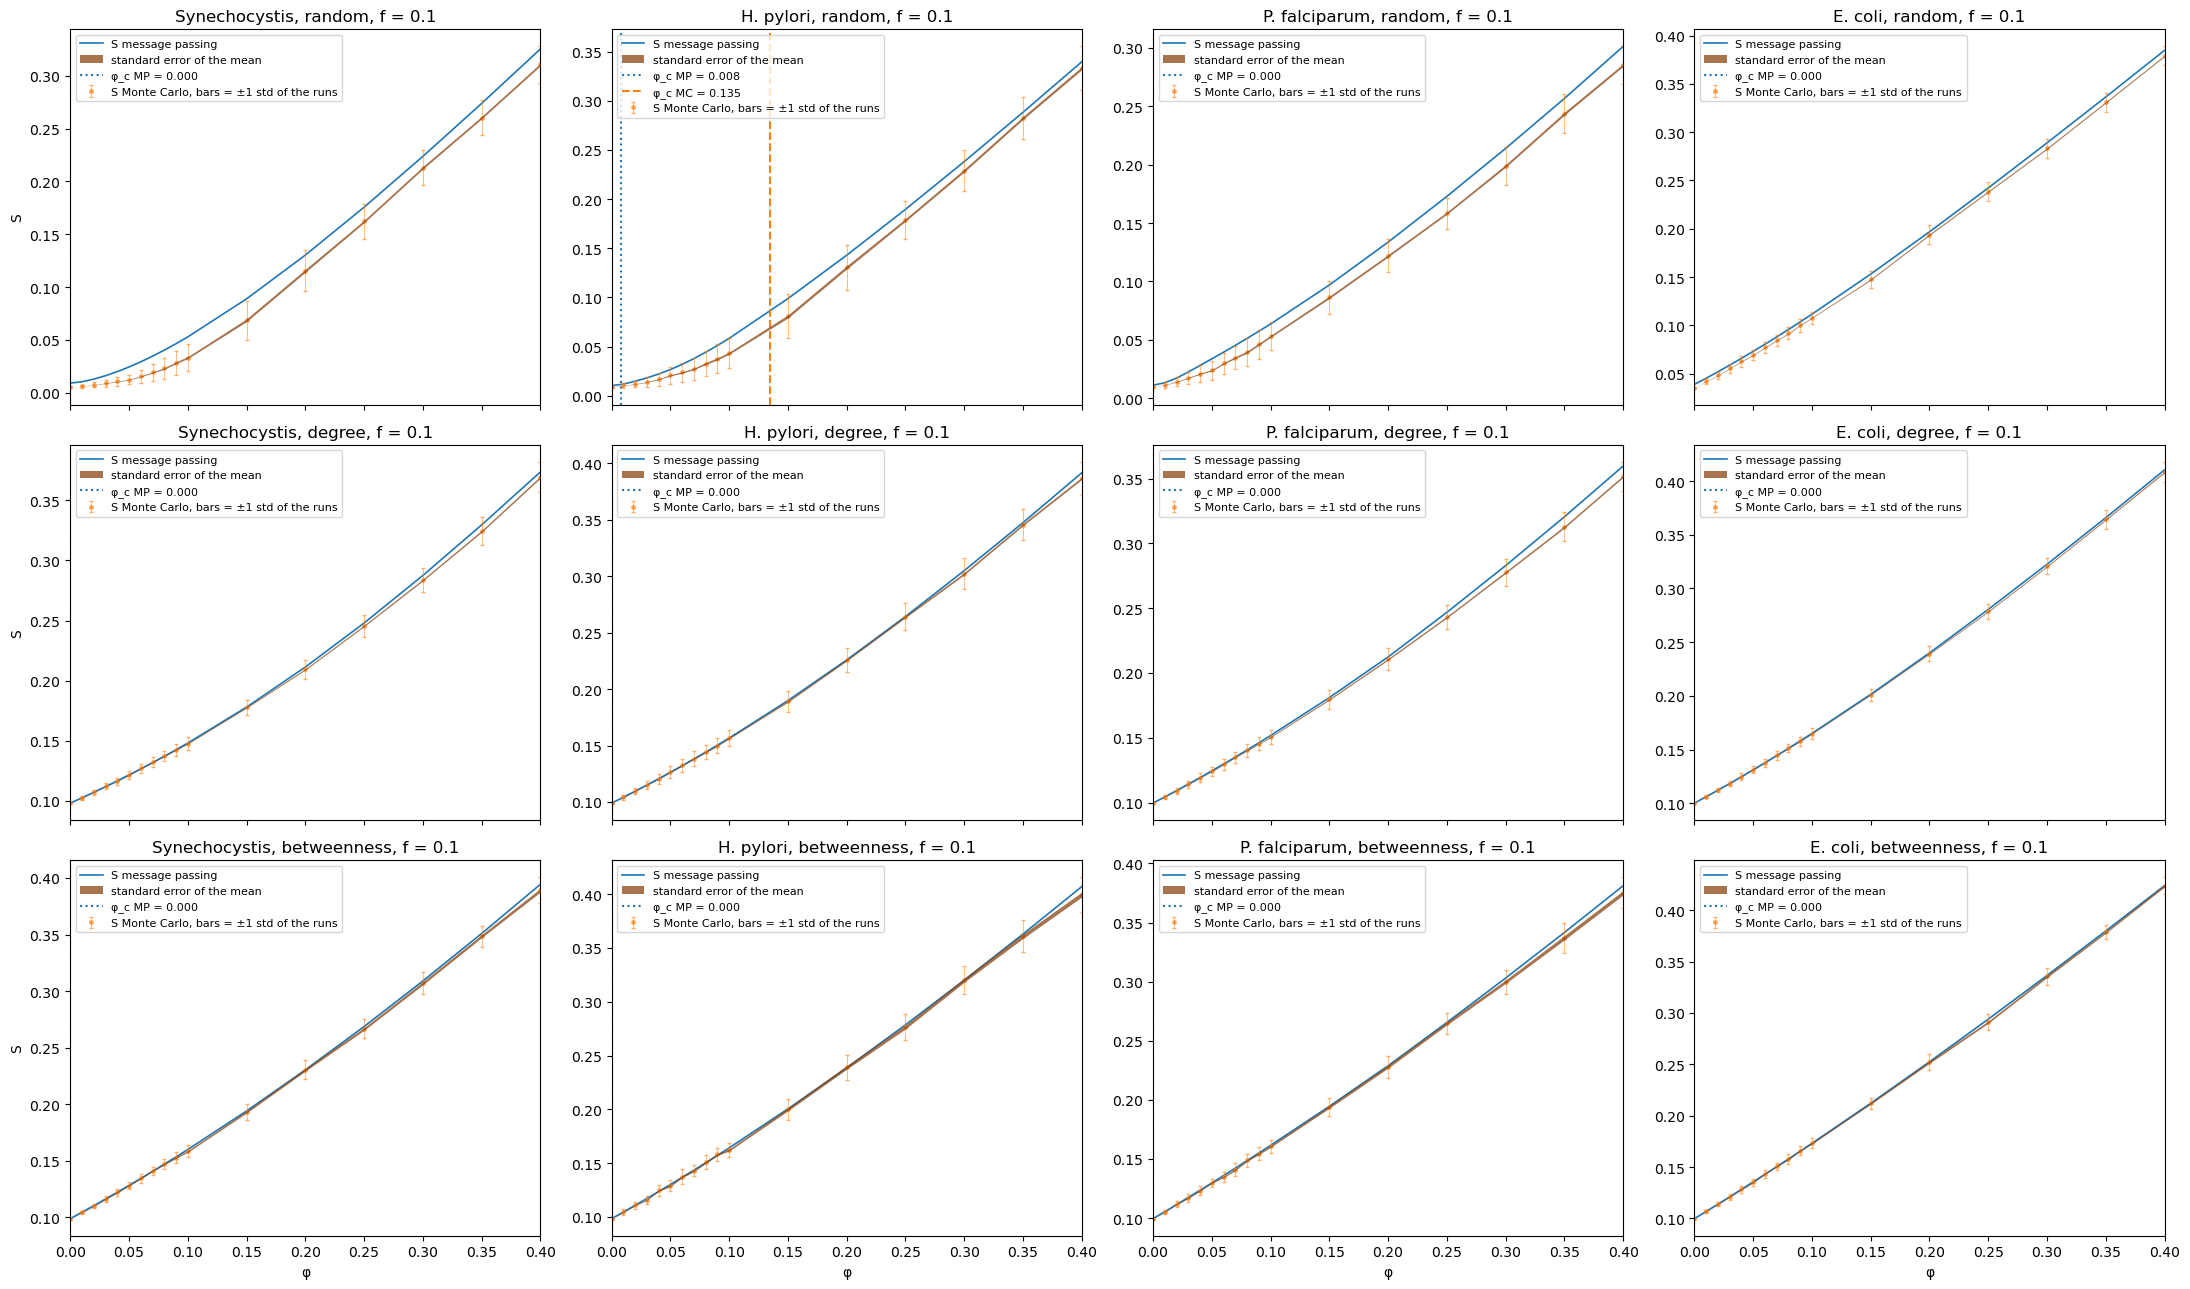

In [24]:
# overview: one row per protocol, one column per network, one colour per f, three values of f
# line: message passing; dots: Monte Carlo mean, bars = ±1 std of the runs; vertical dotted lines: phi_c message passing
frazioni_grafico = [0.001, 0.003, 0.03]
colori = plt.cm.viridis(np.linspace(0, 0.8, len(frazioni_grafico)))
fig, assi = plt.subplots(len(protocolli), len(reti), figsize=(22, 13), sharex=True, sharey=True)
for r, protocollo in enumerate(protocolli):
    for col, nome in enumerate(reti):
        ax = assi[r, col]
        for frazione, c in zip(frazioni_grafico, colori):
            t = curve_5[(curve_5["network"] == nome) & (curve_5["protocol"] == protocollo)
                        & (curve_5["f"] == frazione)]
            ax.plot(t["phi"], t["S MP"], "-", color=c, lw=1.2, label=f"f = {frazione}")
            ax.errorbar(t["phi"], t["S MC"], yerr=t["std"], fmt="o", color=c, ms=2.5, capsize=1.5, lw=0.6)
            ax.axvline(t["phi_c"].iloc[0], color=c, ls=":", lw=1.2)
        ax.set_title(f"{nome}, {protocollo}")
    assi[r, 0].set_ylabel("S")
for ax in assi[-1]:
    ax.set_xlabel("φ")
assi[0, 0].plot([], [], "k:", label="φ_c message passing")
assi[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

# one figure per f, zoom on small phi: dark band = standard error of the Monte Carlo mean, bars = ±1 std of the runs
for frazione in frazioni_5:
    fig, assi = plt.subplots(len(protocolli), len(reti), figsize=(22, 13), sharex=True)
    for r, protocollo in enumerate(protocolli):
        for col, nome in enumerate(reti):
            ax = assi[r, col]
            t = curve_5[(curve_5["network"] == nome) & (curve_5["protocol"] == protocollo)
                        & (curve_5["f"] == frazione)]
            t = t[t["phi"] <= 0.4]
            ax.plot(t["phi"], t["S MP"], "-", color="tab:blue", lw=1.2, label="S message passing")
            ax.errorbar(t["phi"], t["S MC"], yerr=t["std"], fmt="o", color="tab:orange", ms=2.5, capsize=1.5, lw=0.6,
                        alpha=0.6, label="S Monte Carlo, bars = ±1 std of the runs")
            ax.fill_between(t["phi"], t["S MC"] - t["sem"], t["S MC"] + t["sem"], color="saddlebrown", alpha=0.75, lw=0,
                            zorder=3, label="standard error of the mean")
            mc = sintesi_47[(sintesi_47["network"] == nome) & (sintesi_47["protocol"] == protocollo)
                            & (sintesi_47["f"] == frazione)]
            phi_c_mp = mc["phi_c MP"].iloc[0]
            ax.axvline(phi_c_mp, color="tab:blue", ls=":", lw=1.5, label=f"φ_c MP = {phi_c_mp:.3f}")
            ax.axvline(mc["phi_c MC"].iloc[0], color="tab:orange", ls="--", lw=1.5,
                       label=f"φ_c MC = {mc['phi_c MC'].iloc[0]:.3f}")
            ax.set_xlim(0, 0.4)
            ax.set_title(f"{nome}, {protocollo}, f = {frazione}")
            ax.legend(fontsize=8, loc="upper left")
        assi[r, 0].set_ylabel("S")
    for ax in assi[-1]:
        ax.set_xlabel("φ")
    plt.tight_layout()
    plt.show()

In [25]:
# RMS deviation between message passing and Monte Carlo (integral form, non-uniform grid):
# one row per (network, protocol), one column per f
rms_5 = curve_5.groupby(["network", "protocol", "f"], sort=False).apply(
    lambda t: scarto_quadratico_integrale(t["phi"], t["S MP"], t["S MC"]), include_groups=False)
rms_5.unstack("f").round(4)

f                           0.000   0.001   0.003   0.010   0.030   0.050  \
network       protocol                                                      
Synechocystis random       0.0111  0.0111  0.0108  0.0114  0.0108  0.0114   
              degree       0.0117  0.0091  0.0086  0.0070  0.0061  0.0062   
              betweenness  0.0103  0.0090  0.0090  0.0067  0.0053  0.0043   
H. pylori     random       0.0075  0.0082  0.0089  0.0084  0.0088  0.0083   
              degree       0.0087  0.0077  0.0075  0.0041  0.0038  0.0029   
              betweenness  0.0098  0.0075  0.0067  0.0045  0.0029  0.0028   
P. falciparum random       0.0186  0.0189  0.0187  0.0188  0.0187  0.0191   
              degree       0.0188  0.0183  0.0179  0.0178  0.0179  0.0170   
              betweenness  0.0186  0.0176  0.0180  0.0177  0.0163  0.0159   
E. coli       random       0.0047  0.0045  0.0043  0.0043  0.0044  0.0043   
              degree       0.0049  0.0038  0.0035  0.0036  0.0031  0.0028   
              betweenness  0.0051  0.0045  0.0035  0.0036  0.0028  0.0022   

f                           0.100  
network       protocol             
Synechocystis random       0.0112  
              degree       0.0043  
              betweenness  0.0029  
H. pylori     random       0.0078  
              degree       0.0022  
              betweenness  0.0023  
P. falciparum random       0.0193  
              degree       0.0158  
              betweenness  0.0140  
E. coli       random       0.0040  
              degree       0.0024  
              betweenness  0.0019

#### Comment on section 5

The RMS deviation between message passing and Monte Carlo over the whole curve S(φ) is between 0.0019 and 0.0193. It is largest on P. falciparum (0.014 to 0.019), the most fragmented network (56 components, LCC 91%): message passing also counts the components with a cycle other than the largest one (notebook 05, section 3; notebook 07, section 4). For random screening it stays about constant with f on every network (about 0.011 on Synechocystis, 0.008 on H. pylori, 0.019 on P. falciparum, 0.004 on E. coli); for degree and betweenness it decreases as f grows, down to 0.0019 to 0.0043 at f = 0.10 on Synechocystis, H. pylori and E. coli, and to 0.014 and 0.016 on P. falciparum.

## 6. Checks at φ = 0 and drawings

### 6.1 Checks at φ = 0

As in notebook 05, section 1, betweenness screening, `f = 0, 0.001, 0.003` (very few screened nodes) and `0.05, 0.10` as a comparison, `φ = 0`: `S` Monte Carlo (one run
is enough, no randomness is left) and message passing, the largest component of the subgraph of the screened nodes,
the links among them, how many screened nodes have a screened neighbour, and the random baseline (10 draws).

In [26]:
rng_6 = np.random.default_rng(21)      # own generator: the results do not depend on the cells run before
frazioni_6 = [0.0, 0.001, 0.003, 0.05, 0.10]

righe = []
for nome, g in reti.items():
    for f in frazioni_6:
        protetti = estrai_protetti(g, f, "betweenness", rng_6, betw[nome])
        phi_n = phi_ibrido(g, protetti, 0.0)
        S_mc = mc_1run(g, phi_n, rng_6) if f > 0 else 0.0
        S_mp = message_passing(g, phi_n)[0] if f > 0 else 0.0
        H = g.subgraph(protetti)
        lcc_rand = [lcc_protetti(g, estrai_protetti(g, f, "random", rng_6)) for _ in range(10)]
        righe.append({"network": nome, "f": f, "S MC": S_mc, "S MP": S_mp,
                      "LCC screened": lcc_protetti(g, protetti),
                      "links among screened": H.number_of_edges(),
                      "screened with a screened neighbour": sum(1 for n in protetti if H.degree[n] > 0),
                      "LCC random mean": np.mean(lcc_rand), "LCC random max": np.max(lcc_rand)})
controlli_6 = pd.DataFrame(righe)
controlli_6.round(3)

,network,f,S MC,S MP,LCC screened,links among screened,screened with a screened neighbour,LCC random mean,LCC random max
0,Synechocystis,0.000,0.000,0.000,0.000,0,0,0.000,0.000
1,Synechocystis,0.001,0.000,0.000,0.000,0,0,0.000,0.000
2,Synechocystis,0.003,0.001,0.000,0.001,2,4,0.000,0.000
3,Synechocystis,0.050,0.049,0.049,0.049,250,107,0.002,0.005
4,Synechocystis,0.100,0.099,0.099,0.099,568,218,0.007,0.011
5,H. pylori,0.000,0.000,0.000,0.000,0,0,0.000,0.000
6,H. pylori,0.001,0.001,0.000,0.001,0,0,0.001,0.001
7,H. pylori,0.003,0.001,0.000,0.001,0,0,0.001,0.001
8,H. pylori,0.050,0.047,0.047,0.047,94,54,0.003,0.004
9,H. pylori,0.100,0.098,0.098,0.098,271,112,0.006,0.010


### 6.2 What the two methods call the giant component

As in notebook 05, section 3: for each `f`, the components of the subgraph of the screened nodes (betweenness), how
many of them contain a cycle, the nodes in those components and the largest component, as fractions of `N`, against
`S` message passing.

In [27]:
righe = []
for nome, g in reti.items():
    for f in frazioni_6[1:]:
        protetti = estrai_protetti(g, f, "betweenness", rng_6, betw[nome])
        H = g.subgraph(protetti)
        componenti = list(nx.connected_components(H))
        con_cicli = [c for c in componenti if H.subgraph(c).number_of_edges() >= len(c)]   # a tree has |c| - 1 links
        righe.append({"network": nome, "f": f, "components": len(componenti), "with a cycle": len(con_cicli),
                      "nodes in components with a cycle": sum(len(c) for c in con_cicli) / g.number_of_nodes(),
                      "LCC screened": max(len(c) for c in componenti) / g.number_of_nodes(),
                      "S MP": message_passing(g, phi_ibrido(g, protetti, 0.0))[0]})
pd.DataFrame(righe).round(3)

,network,f,components,with a cycle,nodes in components with a cycle,LCC screened,S MP
0,Synechocystis,0.001,2,0,0.000,0.000,0.000
1,Synechocystis,0.003,5,0,0.000,0.001,0.000
2,Synechocystis,0.050,3,1,0.049,0.049,0.049
3,Synechocystis,0.100,2,1,0.099,0.099,0.099
4,H. pylori,0.001,1,0,0.000,0.001,0.000
5,H. pylori,0.003,3,0,0.000,0.001,0.000
6,H. pylori,0.050,4,1,0.047,0.047,0.047
7,H. pylori,0.100,3,1,0.098,0.098,0.098
8,P. falciparum,0.001,1,0,0.000,0.001,0.000
9,P. falciparum,0.003,1,1,0.003,0.003,0.003


### 6.3 Who survives: drawings

Fixed layout of each network (positions of section 1). Removed nodes in light grey; surviving nodes and their links in
orange, darker for the largest component; screened nodes with a black border (`disegna`, from notebook 05, section 2).

1. `φ = 0`: rows betweenness `f = 0.001`, `f = 0.003`, and `f = 0.1` and random `f = 0.1` as a comparison.
2. One Monte Carlo run at `φ` equal to half the threshold of the intact network (`0.5/λ_max`, section 1.1), where
   without screening the giant component is gone: no screening against betweenness `f = 0.001`, `f = 0.003`, and `f = 0.1` as a comparison.

In [28]:
def disegna(ax, g, pos, protetti, phi, titolo, rng):
    """One realisation at phi: removed nodes light grey, surviving nodes orange (the largest component darker),
    screened nodes with a black border."""
    presenti = set(protetti) | {n for n in g.nodes if n not in protetti and rng.random() < phi}
    H = g.subgraph(presenti)
    lcc = max(nx.connected_components(H), key=len) if len(H) else set()
    rimossi = [n for n in g.nodes if n not in presenti]
    nx.draw_networkx_edges(g, pos, ax=ax, edge_color="#dddddd", width=0.2)
    nx.draw_networkx_nodes(g, pos, nodelist=rimossi, ax=ax, node_size=5, node_color="#d9d9d9")
    nx.draw_networkx_edges(H, pos, ax=ax, edge_color="#f5b26b", width=0.6)
    nx.draw_networkx_edges(g.subgraph(lcc), pos, ax=ax, edge_color="#e66101", width=1.0)
    for nodi, colore in [([n for n in presenti if n not in lcc], "#f5b26b"), (list(lcc), "#e66101")]:
        bordo = ["black" if n in protetti else colore for n in nodi]
        nx.draw_networkx_nodes(g, pos, nodelist=nodi, ax=ax, node_size=14, node_color=colore,
                               edgecolors=bordo, linewidths=0.8)
    ax.set_title(f"{titolo}\nS = {len(lcc) / g.number_of_nodes():.3f}", fontsize=11)
    ax.axis("off")

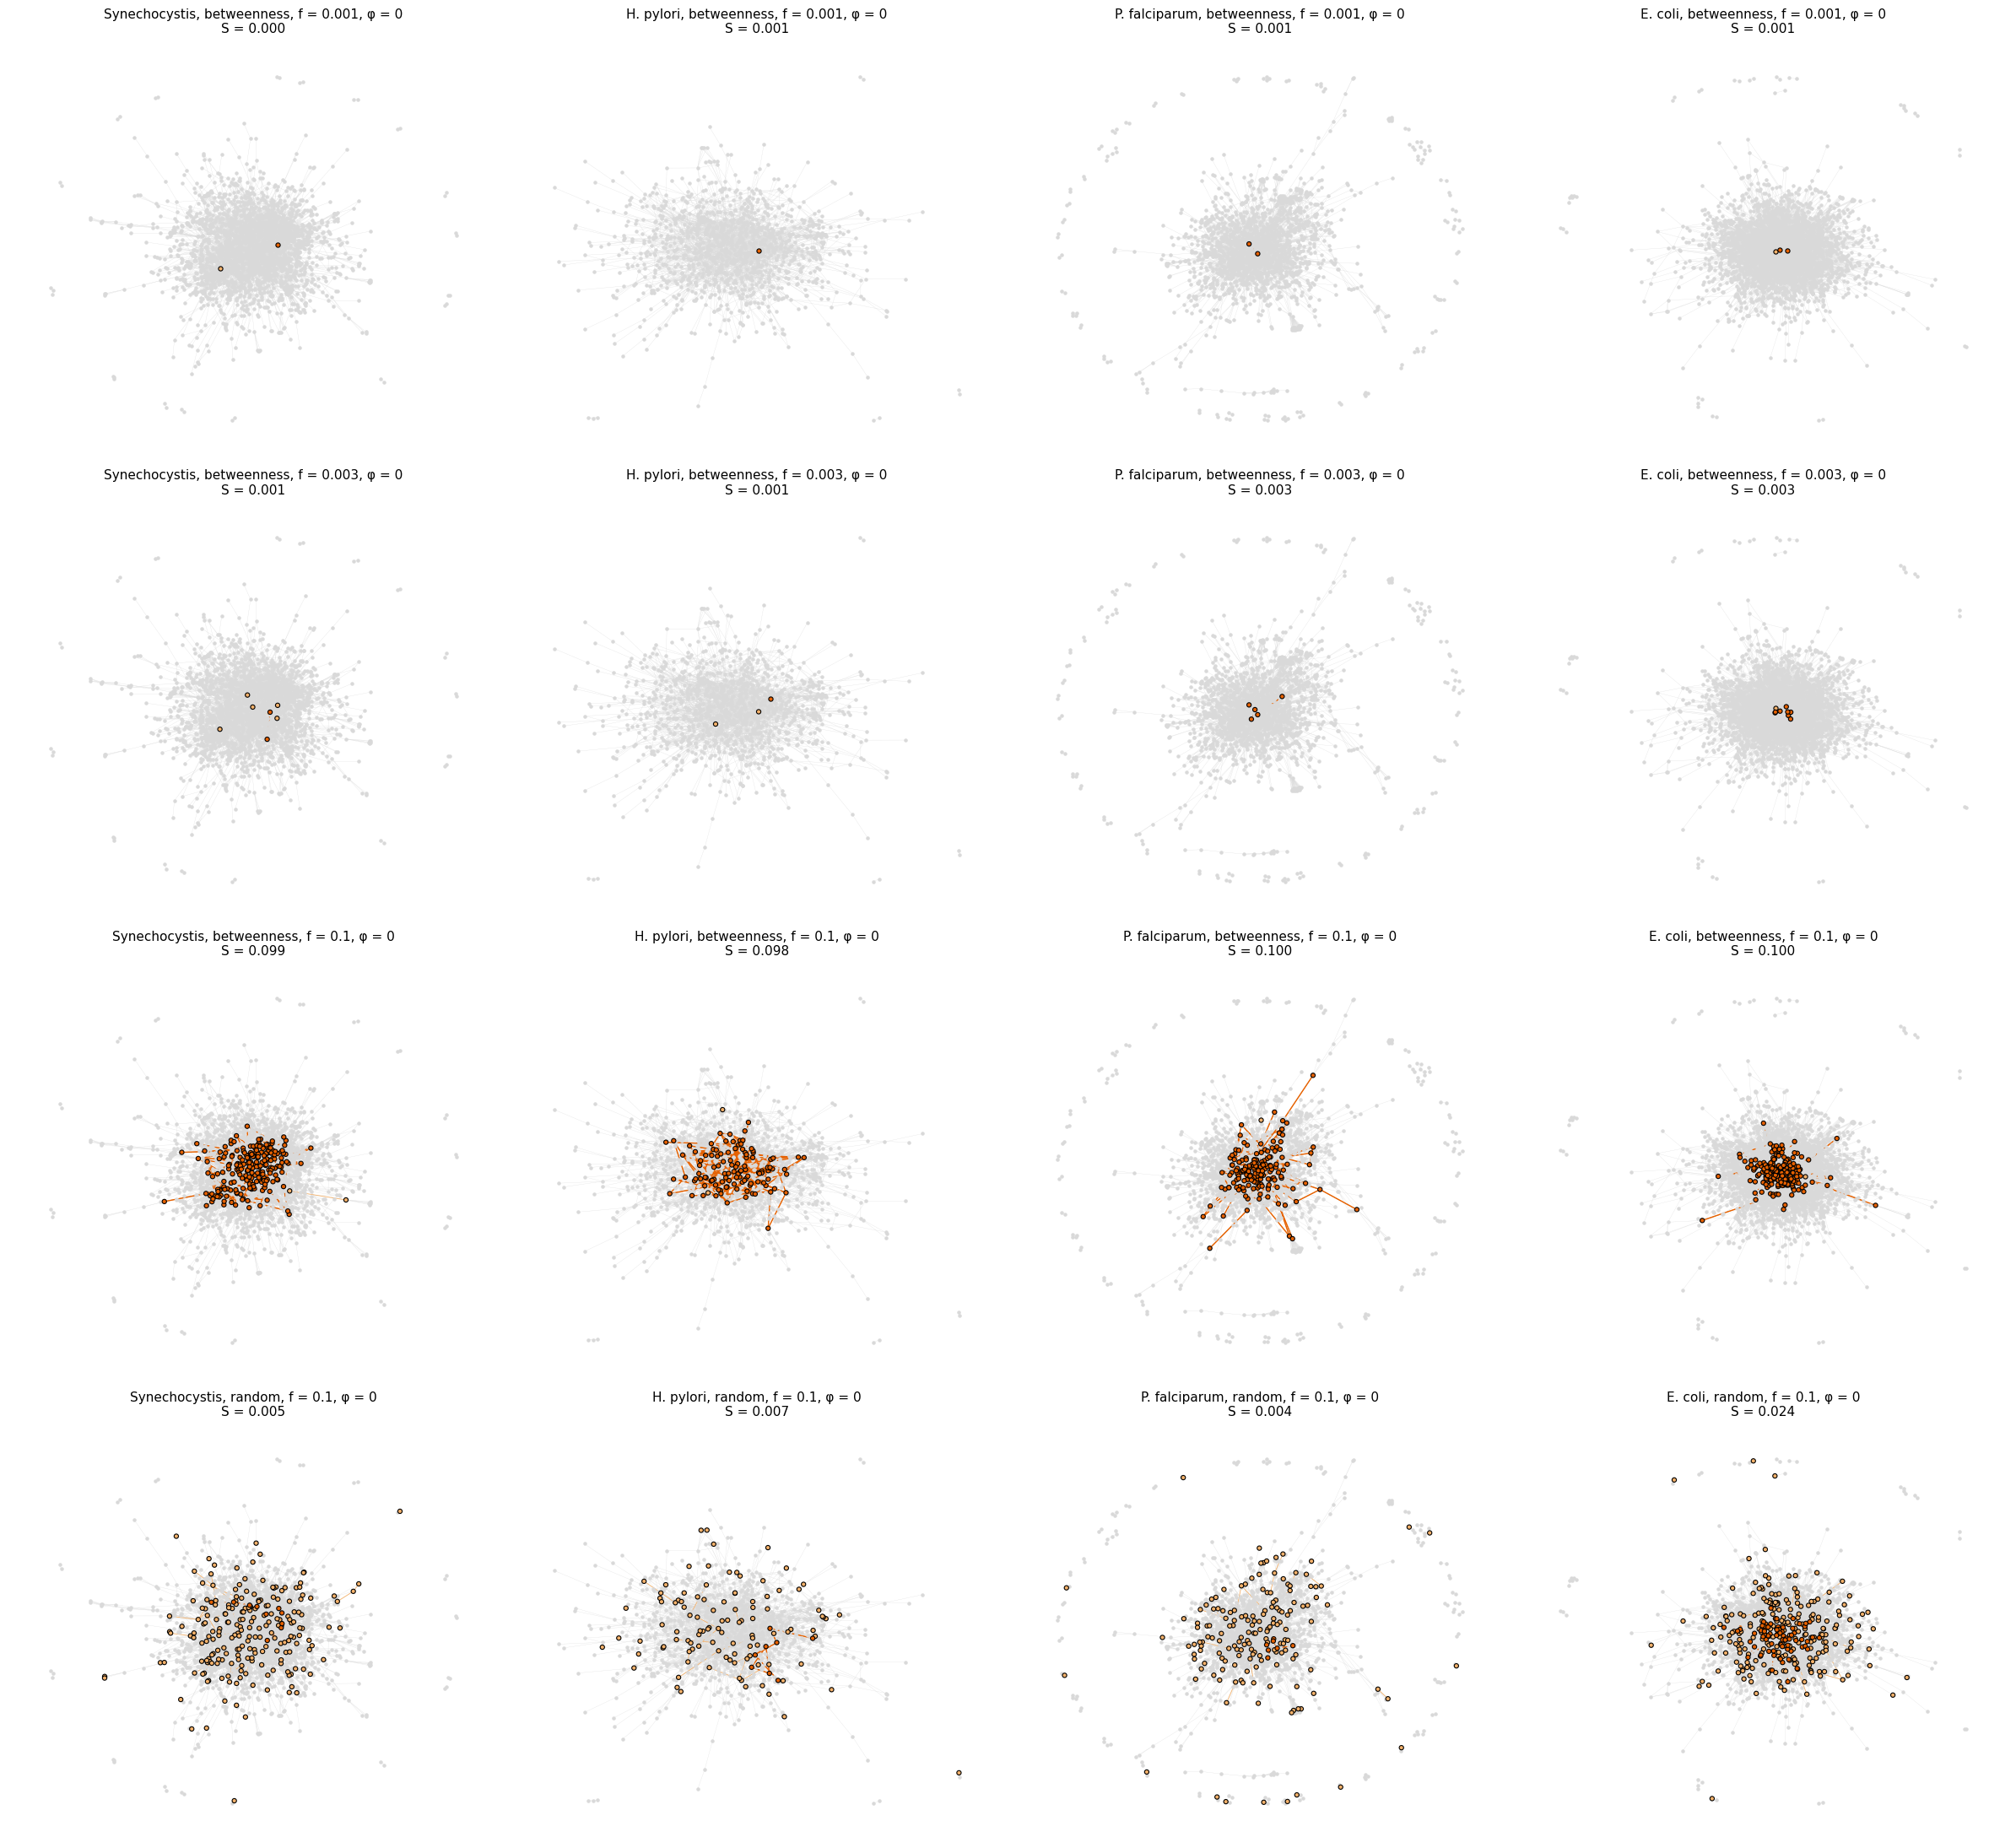

In [29]:
# phi = 0: only the screened nodes survive
casi = [("betweenness", 0.001), ("betweenness", 0.003), ("betweenness", 0.10), ("random", 0.10)]
fig, assi = plt.subplots(len(casi), len(reti), figsize=(24, 22))
for r, (protocollo, f) in enumerate(casi):
    for c, (nome, g) in enumerate(reti.items()):
        protetti = estrai_protetti(g, f, protocollo, rng_6, betw[nome])
        disegna(assi[r, c], g, posizioni[nome], protetti, 0.0, f"{nome}, {protocollo}, f = {f}, φ = 0", rng_6)
plt.tight_layout()
plt.show()

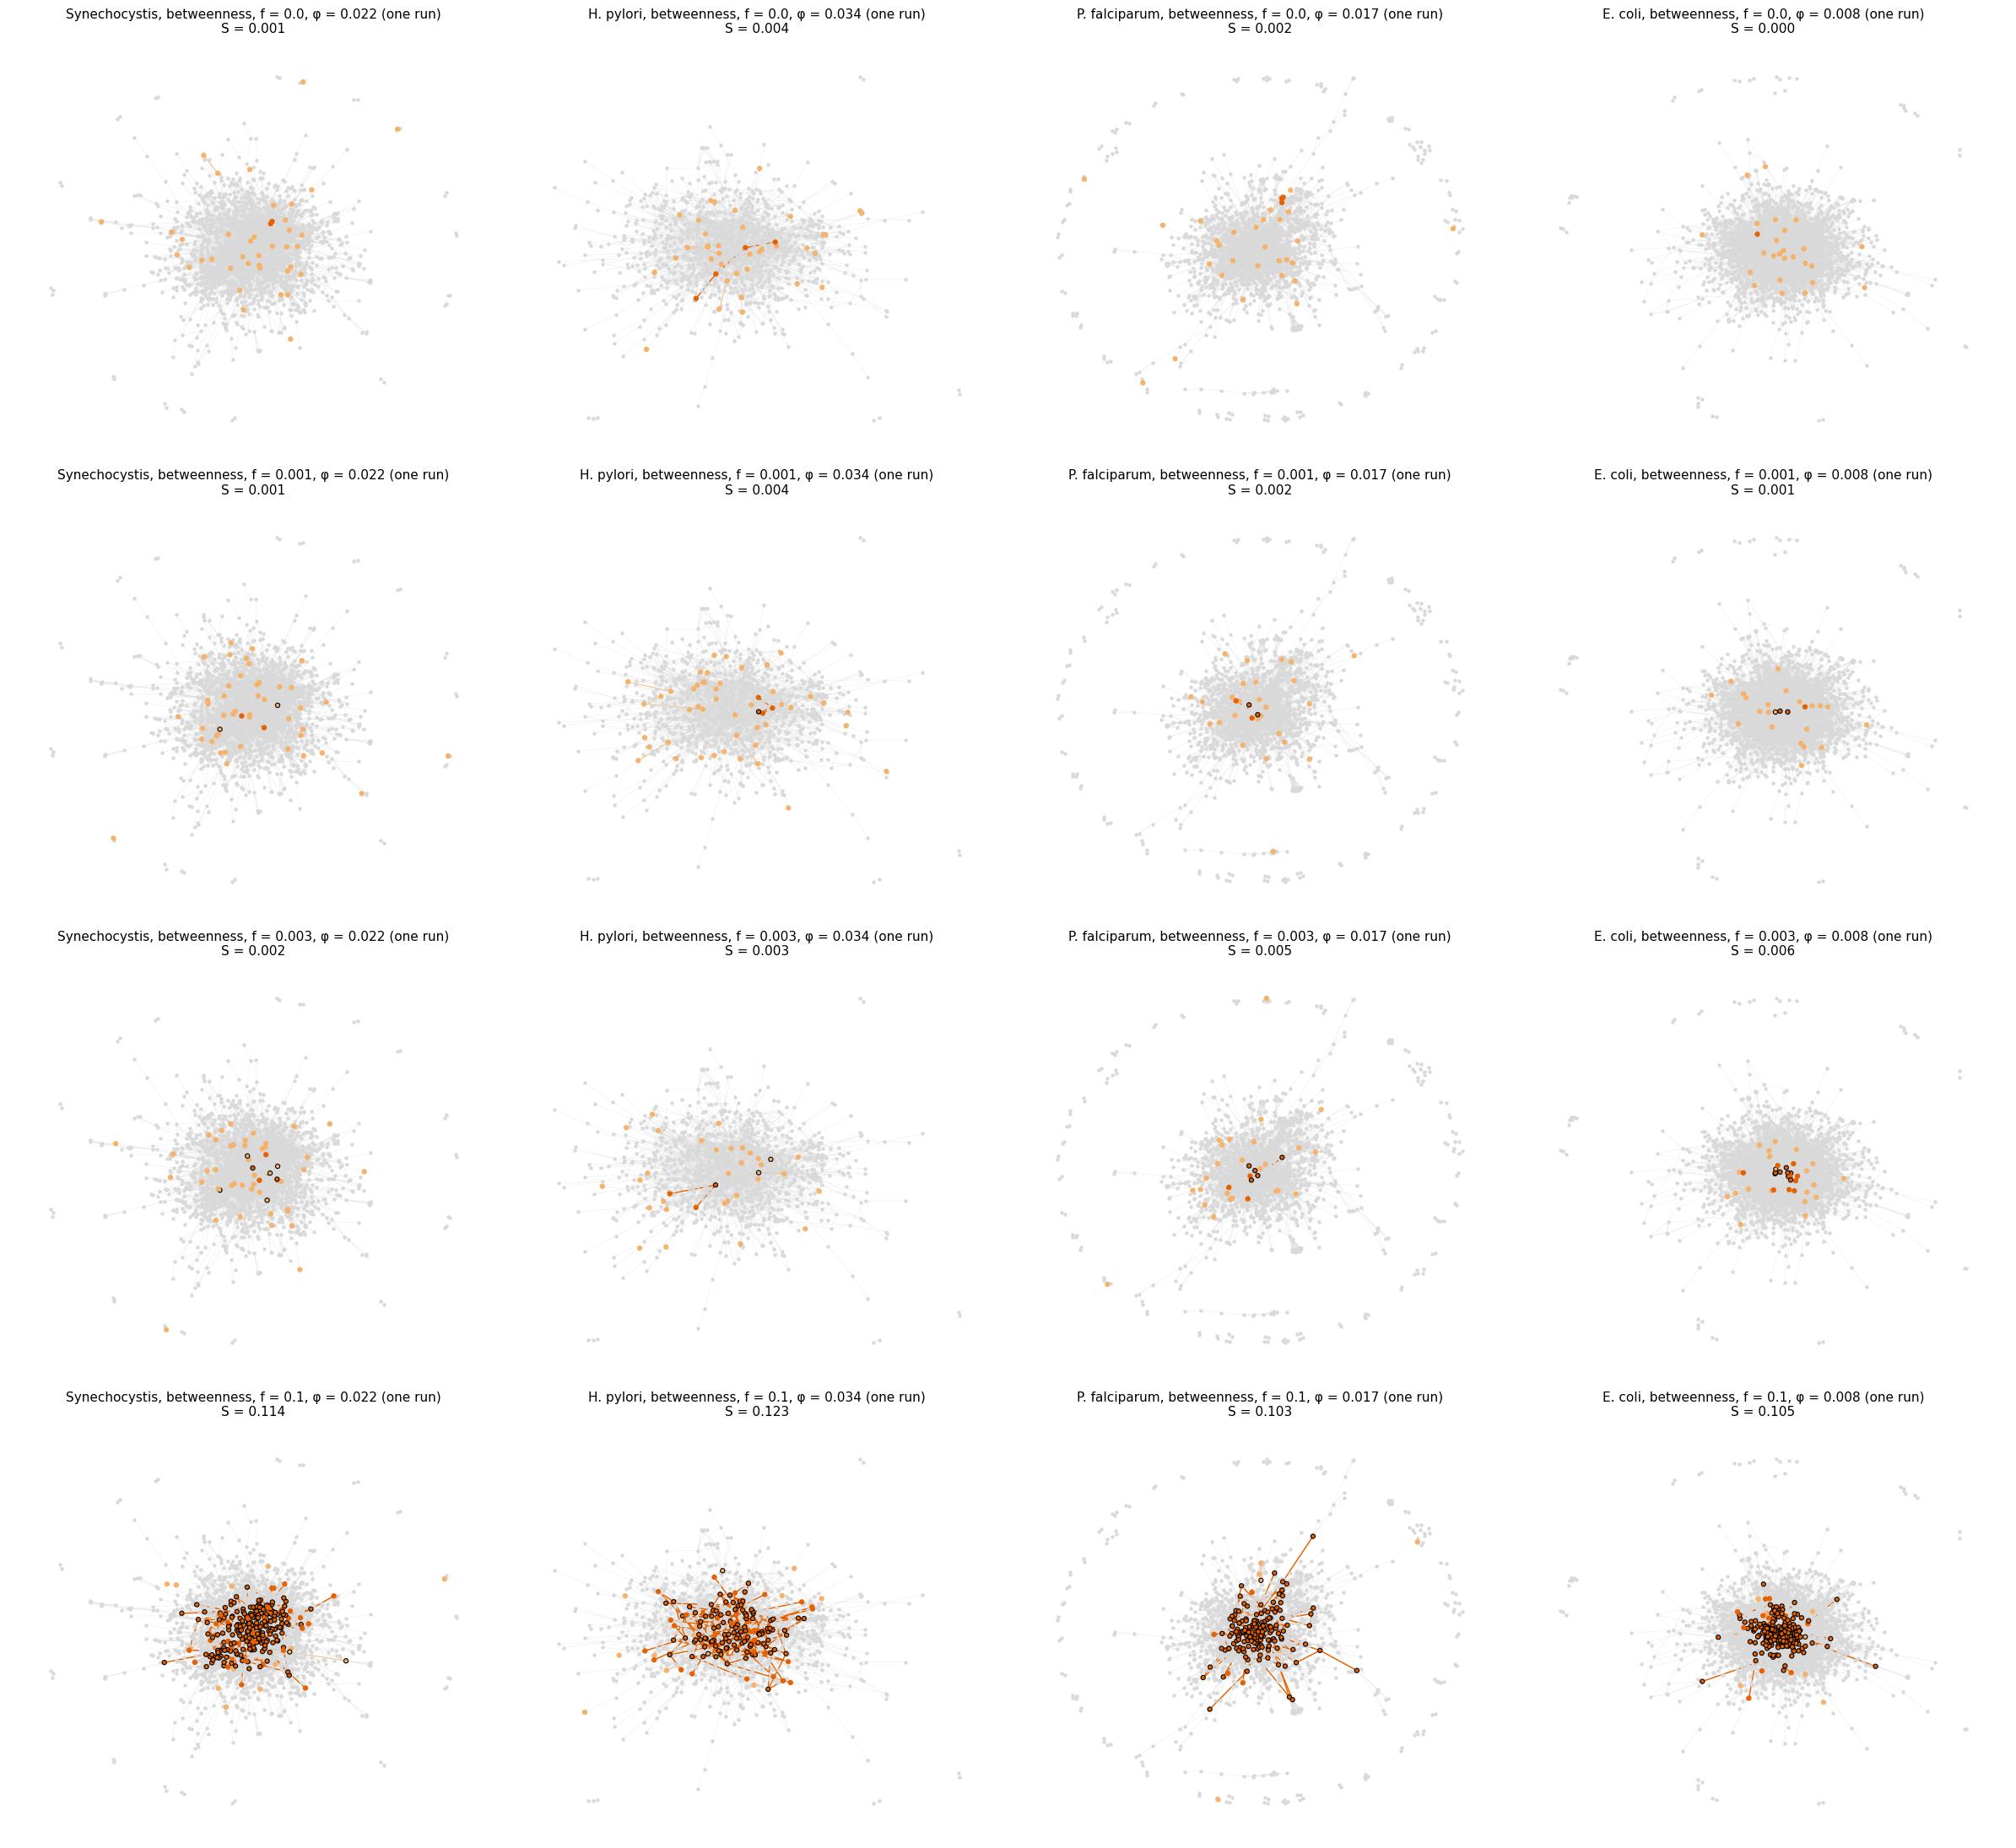

In [30]:
# phi = half the threshold of the intact network: one Monte Carlo run, without and with screening
frazioni_63 = [0.0, 0.001, 0.003, 0.10]
fig, assi = plt.subplots(len(frazioni_63), len(reti), figsize=(24, 22))
for c, (nome, g) in enumerate(reti.items()):
    phi_meta = 0.5 * ispezione.loc[nome, "1/lambda_max"]
    for r, f in enumerate(frazioni_63):
        protetti = estrai_protetti(g, f, "betweenness", rng_6, betw[nome])
        disegna(assi[r, c], g, posizioni[nome], protetti, phi_meta,
                f"{nome}, betweenness, f = {f}, φ = {phi_meta:.3f} (one run)", rng_6)
plt.tight_layout()
plt.show()

#### Comment on section 6

At φ = 0 with betweenness screening, S from Monte Carlo, S from message passing and the LCC of the screened subgraph coincide at f = 0.05 and 0.10 on all four networks (0.099, 0.098, 0.100 and 0.100 at f = 0.10). Random screening of the same number of nodes gives an LCC of at most 0.011, 0.010, 0.011 and 0.047. In every case at most one component of the screened subgraph has a cycle, and it contains all of S_MP. With very few screened nodes (f = 0.001, 0.003) the screened nodes form small trees: Monte Carlo counts the largest one (at most 0.001), message passing gives 0, except on P. falciparum and E. coli at f = 0.003, where the 5 and 9 screened nodes contain a cycle and both methods give 0.003.

## Conclusions

The method of notebooks 03 and 04 runs on four protein interaction networks and passes the same checks: the bisection gives back 1/λ_max, random screening follows φ_eff, and at φ = 0 message passing and Monte Carlo agree with the screened subgraph (section 6).

- **Screening.** Targeted screening of 0.2% to 1% of the proteins removes the threshold (critical budget 0.0020 to 0.0097 with degree or betweenness), 15 to 30 times fewer than random screening. Degree needs slightly fewer nodes on three networks, betweenness on P. falciparum.
- **Curves.** Message passing and Monte Carlo agree on the whole curve S(φ) within RMS 0.002 to 0.011, and 0.014 to 0.019 on P. falciparum, the most fragmented network (LCC 91%).
- **Thresholds.** The Monte Carlo threshold (peak of χ) is far above the message passing one: 0.06 to 0.16 at f = 0, 4 to 15 times the shift measured on Erdos-Renyi networks with the same N and E. Since the curves agree within about 0.01, between the two thresholds S stays small: the two methods put the threshold at two different points of the same curve, and on these networks the threshold may not be the best quantity to compare (notebook 07 compares them with one definition).
- **Where message passing gives φ_c = 0**, the χ peak of Monte Carlo still sits between 0.035 and 0.39: there it marks where the rest of the network joins the screened core, not the birth of a giant component.